## Plan du notebook

1. Configuration et imports
2. Chargement des données
3. Visualisation du dataset
4. Définition de la tâche et des variables
5. Fonctions utilitaires
6. Baselines (scores à battre)
7. Entraînement des modèles
8. Réglage des hyperparamètres
9. Comparaison des modèles
10. Sélection du meilleur modèle (grille pondérée)
11. Évaluation finale sur le jeu de test
12. Interprétabilité et sauvegarde du modèle
13. Conclusion

**Règle de méthode :** le jeu de test n'est utilisé qu'une seule fois, à l'étape 11. Tous les choix (modèles, hyperparamètres) se font sur le train et la validation.

## 1. Configuration et imports

Objectif : charger les bibliothèques et fixer la graine aléatoire (`SEED = 42`) pour que les résultats soient reproductibles par toute l'équipe.

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

SEED = 42
np.random.seed(SEED)

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (11, 4)

print("pandas", pd.__version__, "| numpy", np.__version__)

Matplotlib is building the font cache; this may take a moment.


pandas 3.1.1 | numpy 2.5.4


## 2. Chargement des données

Objectif : charger les trois fichiers `train.csv`, `val.csv`, `test.csv`.

- `train` (70 %) : apprentissage des modèles
- `val` (15 %) : réglage des hyperparamètres et comparaison
- `test` (15 %) : évaluation finale, utilisé une seule fois



In [6]:
train = pd.read_csv("../data/processed/train.csv", parse_dates=["datetime"])
val   = pd.read_csv("../data/processed/val.csv",   parse_dates=["datetime"])
test  = pd.read_csv("../data/processed/test.csv",  parse_dates=["datetime"])

print("train :", train.shape)
print("val   :", val.shape)
print("test  :", test.shape)

train : (24374, 14)
val   : (5223, 14)
test  : (5223, 14)


In [7]:
train.head()

,datetime,traffic_flow,speed_kmh,week_day,holidays,temp_celsius,wind_speed_kmh,precip_mm,weather_condition,hour,minute,is_weekend,traffic_flow_lag_1,traffic_flow_lag_3
0,2020-02-01 00:15:00,337,105.25,6,1,12.78,4.83,0.0,Fair,0,15,1,347.0,338.0
1,2020-02-01 00:20:00,302,106.70,6,1,12.78,4.83,0.0,Fair,0,20,1,337.0,360.0
2,2020-02-01 00:25:00,282,105.09,6,1,12.78,4.83,0.0,Fair,0,25,1,302.0,347.0
3,2020-02-01 00:30:00,302,106.54,6,1,12.78,4.83,0.0,Fair,0,30,1,282.0,337.0
4,2020-02-01 00:35:00,277,106.54,6,1,12.78,4.83,0.0,Fair,0,35,1,302.0,302.0


In [8]:
resume = pd.DataFrame({
    "lignes": [len(train), len(val), len(test)],
    "début": [train.datetime.min(), val.datetime.min(), test.datetime.min()],
    "fin": [train.datetime.max(), val.datetime.max(), test.datetime.max()],
    "débit moyen": [round(d.traffic_flow.mean(), 1) for d in (train, val, test)],
    "valeurs manquantes": [int(d.isna().sum().sum()) for d in (train, val, test)],
}, index=["train", "val", "test"])
resume

,lignes,début,fin,débit moyen,valeurs manquantes
train,24374,2020-02-01 00:15:00,2020-04-25 17:25:00,416.0,0
val,5223,2020-04-25 17:30:00,2020-05-13 20:40:00,377.6,0
test,5223,2020-05-13 20:45:00,2020-05-31 23:55:00,406.3,0


**Observation :** les trois jeux se suivent dans le temps et ne contiennent aucune valeur manquante. Le débit moyen de la validation (≈ 378) est plus bas que celui du train (≈ 416) : cela reflète la baisse du trafic liée à la COVID-19 en mars-avril 2020, que nous retrouverons dans les graphiques de la section 3.

## 3. Visualisation du dataset

Objectif : comprendre le comportement du trafic avant d'entraîner les modèles. Nous regardons l'évolution dans le temps, les rythmes journaliers et hebdomadaires, la distribution du débit, les corrélations et l'effet de la météo.

In [9]:
# Ajout d'une colonne "jeu" pour distinguer train / val / test dans les graphiques
train["jeu"], val["jeu"], test["jeu"] = "train", "val", "test"
full = pd.concat([train, val, test], ignore_index=True)

# Ordre des jours pour les graphiques (1 = lundi ... 7 = dimanche)
jours = {1: "Lun", 2: "Mar", 3: "Mer", 4: "Jeu", 5: "Ven", 6: "Sam", 7: "Dim"}

print(full.shape)

(34820, 15)


### 3.1 Évolution du débit dans le temps

Débit moyen par jour, avec les trois jeux en couleurs différentes. Ce graphique montre où tombent les coupures chronologiques et le changement de régime du trafic.

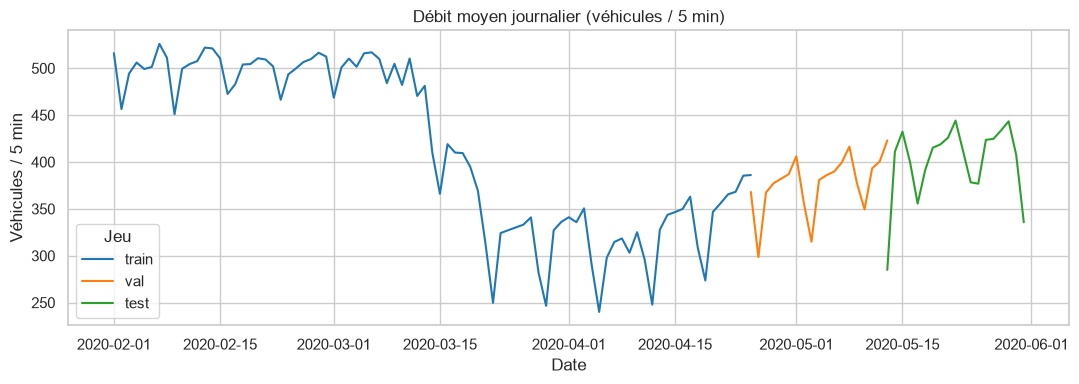

In [10]:
fig, ax = plt.subplots()
couleurs = {"train": "tab:blue", "val": "tab:orange", "test": "tab:green"}

for nom, c in couleurs.items():
    j = full[full["jeu"] == nom].set_index("datetime")["traffic_flow"].resample("D").mean()
    ax.plot(j.index, j.values, color=c, label=nom)

ax.set_title("Débit moyen journalier (véhicules / 5 min)")
ax.set_xlabel("Date")
ax.set_ylabel("Véhicules / 5 min")
ax.legend(title="Jeu")
plt.tight_layout()
plt.show()

**Observation :** le débit chute fortement entre février et avril 2020 (confinement lié à la COVID-19), puis remonte en mai. Le jeu d'entraînement contient donc deux régimes de trafic différents, la validation tombe dans la période creuse puis la reprise, et le test correspond à une reprise partielle. Les scores obtenus sur le test ne reflètent donc pas une année normale, et nous le préciserons dans la conclusion.

### 3.2 Profil horaire : semaine contre week-end

Débit moyen par heure de la journée, séparé entre jours de semaine et week-end. Ce graphique montre le rythme journalier du trafic et justifie l'usage de `hour` et `is_weekend` comme variables.

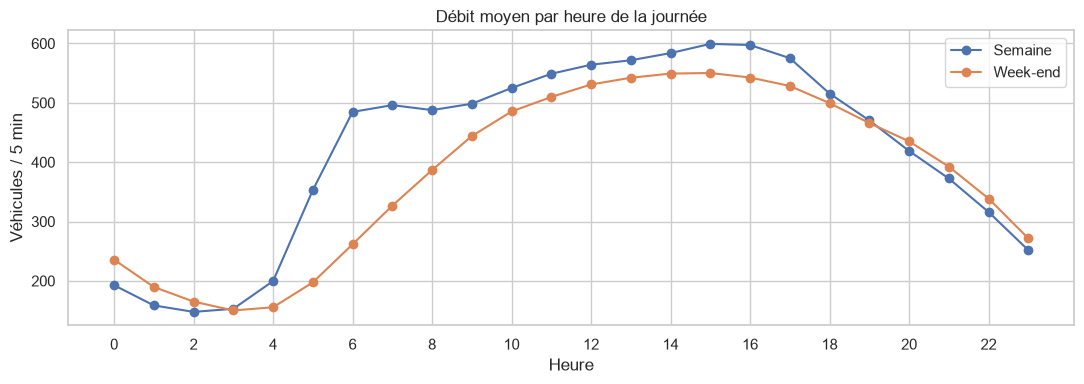

In [11]:
profil = full.groupby(["is_weekend", "hour"])["traffic_flow"].mean().unstack(0)
profil.columns = ["Semaine", "Week-end"]

ax = profil.plot(marker="o")
ax.set_title("Débit moyen par heure de la journée")
ax.set_xlabel("Heure")
ax.set_ylabel("Véhicules / 5 min")
ax.set_xticks(range(0, 24, 2))
plt.tight_layout()
plt.show()

**Observation :** les deux courbes ne se ressemblent pas. Complétez ici en regardant votre graphique : à quelle heure le débit est-il le plus bas la nuit, à quelle heure atteint-il son maximum en semaine, et en quoi le week-end diffère-t-il ?

Conclusion : le trafic suit un rythme journalier marqué qui dépend du type de jour, donc `hour` et `is_weekend` seront des variables importantes pour les modèles.

### 3.3 Carte de chaleur : jour de la semaine × heure

Débit moyen pour chaque combinaison jour de la semaine et heure. Ce graphique est l'un de ceux demandés dans le cahier des charges (page 2 du dashboard), et il montre d'un seul coup d'œil les heures de pointe.

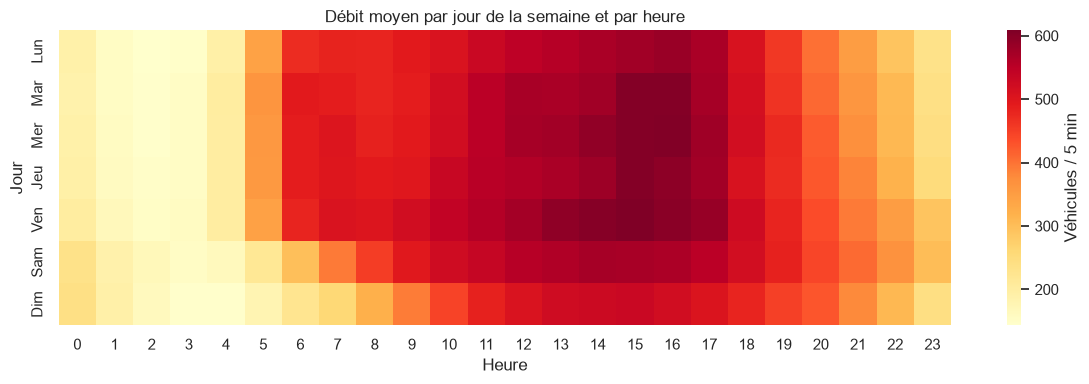

In [12]:
chaleur = full.pivot_table(index="week_day", columns="hour",
                           values="traffic_flow", aggfunc="mean")
chaleur.index = [jours[j] for j in chaleur.index]

plt.figure(figsize=(12, 4))
sns.heatmap(chaleur, cmap="YlOrRd", cbar_kws={"label": "Véhicules / 5 min"})
plt.title("Débit moyen par jour de la semaine et par heure")
plt.xlabel("Heure")
plt.ylabel("Jour")
plt.tight_layout()
plt.show()

**Observation :** (à compléter) Quelles plages horaires sont les plus foncées en semaine ? Le samedi et le dimanche ont-ils la même forme ? Repérez aussi les créneaux de nuit les plus calmes.

Conclusion : les heures de pointe se concentrent sur certains créneaux précis, ce qui confirme l'intérêt de variables temporelles pour prédire le trafic et pour adapter la durée des feux.

### 3.4 Distribution du débit

Histogramme des valeurs de `traffic_flow` (la variable à prédire) et statistiques descriptives. Il permet de voir si le débit est concentré autour d'une valeur ou réparti en plusieurs groupes.

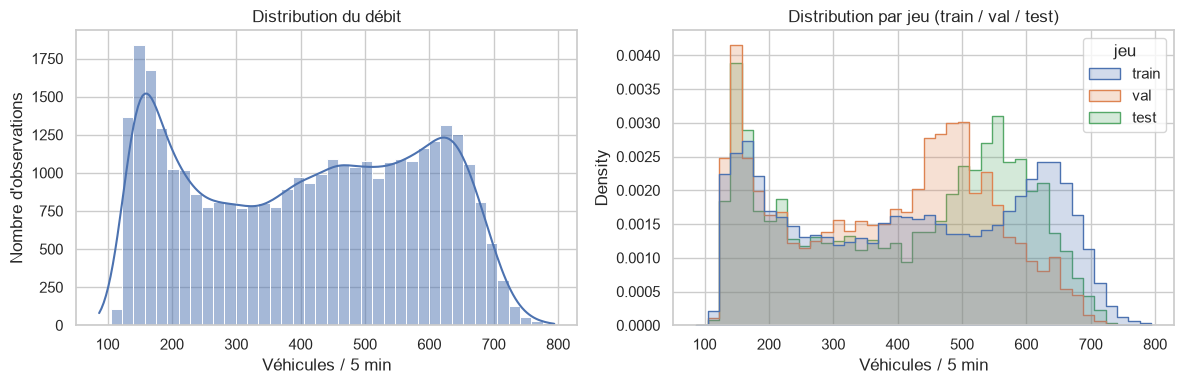

count    34820.0
mean       408.7
std        179.0
min         87.0
25%        237.0
50%        421.0
75%        568.0
max        794.0
Name: traffic_flow, dtype: float64

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(full["traffic_flow"], bins=40, kde=True, ax=axes[0])
axes[0].set_title("Distribution du débit")
axes[0].set_xlabel("Véhicules / 5 min")
axes[0].set_ylabel("Nombre d'observations")

sns.histplot(data=full, x="traffic_flow", hue="jeu", bins=40, element="step",
             stat="density", common_norm=False, ax=axes[1])
axes[1].set_title("Distribution par jeu (train / val / test)")
axes[1].set_xlabel("Véhicules / 5 min")

plt.tight_layout()
plt.show()

full["traffic_flow"].describe().round(1)

**Observation :** (à compléter) La distribution a-t-elle une seule bosse ou plusieurs ? Les trois jeux ont-ils des distributions proches ou le val et le test sont-ils décalés par rapport au train ?

Conclusion : le débit varie de 87 à 794 véhicules par 5 minutes, avec une forte dispersion (écart-type d'environ 179). Une prédiction qui se contente de la moyenne globale (≈ 409) serait donc très imprécise.

### 3.5 Matrice de corrélation

Corrélation linéaire entre les variables numériques et le débit. Elle indique quelles variables sont liées à la cible, et lesquelles sont redondantes entre elles.

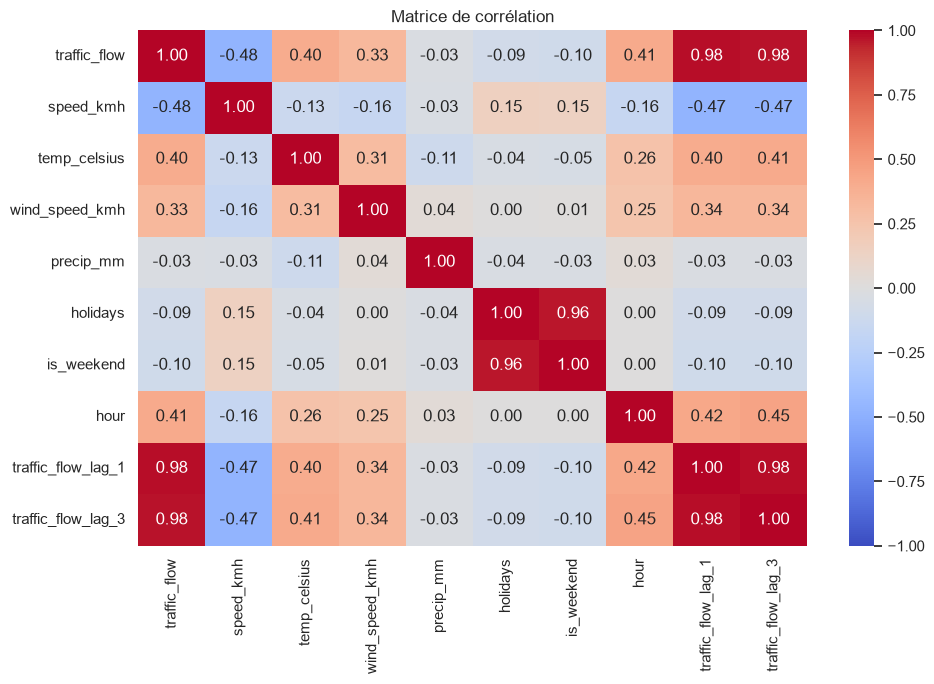

In [14]:
colonnes_corr = ["traffic_flow", "speed_kmh", "temp_celsius", "wind_speed_kmh",
                 "precip_mm", "holidays", "is_weekend", "hour",
                 "traffic_flow_lag_1", "traffic_flow_lag_3"]

plt.figure(figsize=(10, 7))
sns.heatmap(full[colonnes_corr].corr(), annot=True, fmt=".2f",
            cmap="coolwarm", center=0, vmin=-1, vmax=1)
plt.title("Matrice de corrélation")
plt.tight_layout()
plt.show()

In [15]:
full[colonnes_corr].corr()["traffic_flow"].drop("traffic_flow").sort_values(ascending=False).round(3)

traffic_flow_lag_1    0.984
traffic_flow_lag_3    0.975
hour                  0.412
temp_celsius          0.400
wind_speed_kmh        0.334
precip_mm            -0.029
holidays             -0.092
is_weekend           -0.097
speed_kmh            -0.475
Name: traffic_flow, dtype: float64

**Observation :**

- `traffic_flow_lag_1` est presque parfaitement corrélée au débit (≈ 0,98) : le trafic change peu en 5 minutes. Un modèle qui reprend simplement la valeur précédente sera déjà très bon, c'est pourquoi la baseline de **persistance** (section 6) est le vrai score à battre.
- `speed_kmh` est corrélée négativement au débit (≈ −0,48). Cependant, elle est mesurée **au même instant** que la cible : en situation réelle, on ne la connaît pas avant de prédire. Nous **l'excluons des variables d'entrée** pour éviter une fuite de données.
- `holidays` et `is_weekend` sont presque identiques (≈ 98 % de lignes égales) : elles apportent la même information.
- (à compléter) Que remarquez-vous pour `temp_celsius`, `wind_speed_kmh` et `precip_mm` ? Leur corrélation avec le débit est-elle forte ou faible ?

### 3.6 Effet de la météo sur le débit

Distribution du débit selon l'état du ciel (`weather_condition`), sous forme de boîtes à moustaches, avec le nombre d'observations de chaque catégorie. Certaines catégories sont très rares, donc il faut les interpréter avec prudence.

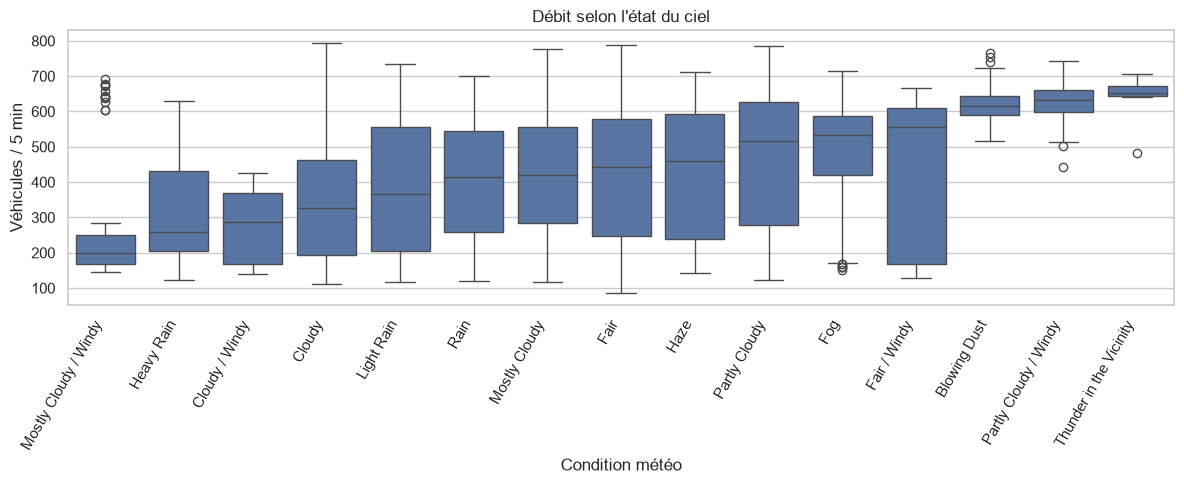

In [16]:
ordre = full.groupby("weather_condition")["traffic_flow"].median().sort_values().index

plt.figure(figsize=(12, 5))
sns.boxplot(data=full, x="weather_condition", y="traffic_flow", order=ordre)
plt.xticks(rotation=60, ha="right")
plt.title("Débit selon l'état du ciel")
plt.xlabel("Condition météo")
plt.ylabel("Véhicules / 5 min")
plt.tight_layout()
plt.show()

In [17]:
effectifs = (full.groupby(["weather_condition", "jeu"]).size().unstack(fill_value=0)
             .reindex(columns=["train", "val", "test"]))
effectifs["total"] = effectifs.sum(axis=1)
effectifs["débit moyen"] = full.groupby("weather_condition")["traffic_flow"].mean().round(1)
effectifs.sort_values("total", ascending=False)

jeu,train,val,test,total,débit moyen
weather_condition,,,,,
Fair,13634,4671,4431,22736,420.1
Cloudy,4464,312,492,5268,341.8
Mostly Cloudy,1944,96,132,2172,414.7
Partly Cloudy,1920,72,60,2052,461.5
Light Rain,1404,0,72,1476,384.6
Rain,432,0,24,456,403.8
Haze,120,60,12,192,431.1
Heavy Rain,120,0,0,120,310.3
Fair / Windy,72,0,0,72,432.2


**Observation :**

- Le débit moyen varie selon l'état du ciel, mais **ce graphique ne prouve pas que la météo cause ces écarts**. Les conditions rares (`Blowing Dust`, `Fog`...) n'apparaissent que sur quelques heures, souvent en février, quand le trafic était élevé, avant la chute liée à la COVID-19. La météo est donc mélangée avec la période.
- Certaines catégories n'existent que dans un seul jeu. Le prétraitement devra gérer les catégories inconnues (`OneHotEncoder(handle_unknown="ignore")`), sinon le modèle échouerait sur la validation ou le test.
- (à compléter) Quelles conditions ont le débit médian le plus bas et le plus haut ? Les catégories les plus fréquentes (`Fair`, `Cloudy`) se ressemblent-elles ?

Conclusion : la météo est une variable à garder, mais on ne doit pas s'attendre à ce qu'elle soit déterminante. L'heure, le jour et le niveau récent du trafic expliquent l'essentiel de la variation.

## 4. Définition de la tâche et des variables

**Tâche :** régression. Nous prédisons `traffic_flow`, le nombre de véhicules par intervalle de 5 minutes.

**Deux scénarios**, correspondant à deux usages du projet :

| Scénario | Variables d'entrée | Usage |
|---|---|---|
| **A, prévision à court terme** | calendrier + météo + débit à t−5 min et t−15 min (`lag_1`, `lag_3`) | régulation des feux en temps réel |
| **B, scénario sans historique** | calendrier + météo uniquement | page 6 du dashboard (l'utilisateur saisit date, heure et météo) |

**Décisions de méthode :**

- `speed_kmh` est **exclue** : elle est mesurée au même instant que la cible, donc inconnue au moment de la prédiction (fuite de données).
- `datetime` et la colonne `jeu` (ajoutée pour les graphiques) ne sont pas des variables d'entrée.
- L'heure, la minute et le jour de la semaine sont **encodés de façon cyclique** (sinus et cosinus), pour que 23 h et 0 h soient proches, ce qui aide les modèles sensibles aux distances (KNN, SVM, MLP).
- `weather_condition` (texte) est encodée plus tard, dans une pipeline ajustée sur le train seulement.

In [18]:
def ajouter_variables_cycliques(df):
    """Encodage sinus/cosinus de l'heure, de la minute et du jour de la semaine."""
    df = df.copy()
    df["hour_sin"]    = np.sin(2 * np.pi * df["hour"] / 24)
    df["hour_cos"]    = np.cos(2 * np.pi * df["hour"] / 24)
    df["minute_sin"]  = np.sin(2 * np.pi * df["minute"] / 60)
    df["minute_cos"]  = np.cos(2 * np.pi * df["minute"] / 60)
    df["weekday_sin"] = np.sin(2 * np.pi * (df["week_day"] - 1) / 7)
    df["weekday_cos"] = np.cos(2 * np.pi * (df["week_day"] - 1) / 7)
    return df

train = ajouter_variables_cycliques(train)
val   = ajouter_variables_cycliques(val)
test  = ajouter_variables_cycliques(test)

train[["hour", "hour_sin", "hour_cos", "week_day", "weekday_sin", "weekday_cos"]].head()

,hour,hour_sin,hour_cos,week_day,weekday_sin,weekday_cos
0,0,0.0,1.0,6,-0.974928,-0.222521
1,0,0.0,1.0,6,-0.974928,-0.222521
2,0,0.0,1.0,6,-0.974928,-0.222521
3,0,0.0,1.0,6,-0.974928,-0.222521
4,0,0.0,1.0,6,-0.974928,-0.222521


In [19]:
cible = "traffic_flow"
cat   = ["weather_condition"]

num_base = ["temp_celsius", "wind_speed_kmh", "precip_mm", "holidays", "is_weekend",
            "hour_sin", "hour_cos", "minute_sin", "minute_cos",
            "weekday_sin", "weekday_cos"]
lags = ["traffic_flow_lag_1", "traffic_flow_lag_3"]

num_A, num_B = num_base + lags, num_base
features_A, features_B = num_A + cat, num_B + cat

# Contrôle anti-fuite : aucune de ces colonnes ne doit servir d'entrée
interdites = {"traffic_flow", "speed_kmh", "datetime", "jeu"}
for nom, f in [("A", features_A), ("B", features_B)]:
    assert not interdites & set(f), f"Colonne interdite dans le scénario {nom}"

y_train, y_val, y_test = train[cible], val[cible], test[cible]

print("Scénario A :", len(features_A), "variables")
print("Scénario B :", len(features_B), "variables")

Scénario A : 14 variables
Scénario B : 12 variables


**Décisions retenues :**

- Cible : `traffic_flow` (régression), évaluée avec MAE, RMSE et R².
- Scénario A : 14 variables, dont `traffic_flow_lag_1` et `traffic_flow_lag_3`.
- Scénario B : 12 variables, sans historique de débit.
- `speed_kmh` exclue (fuite de données).
- `holidays` et `is_weekend` sont presque identiques ; nous gardons les deux, ce qui est sans effet pour les arbres et marginal pour les modèles linéaires.

**Point d'attention :** (à compléter après les résultats) le scénario B ne voit pas le niveau actuel du trafic. Avec le changement de régime lié à la COVID-19, il risque de moins bien faire que de simples baselines. Nous comparerons donc toujours chaque modèle aux baselines de la section 6.

## 5. Fonctions utilitaires

Objectif : écrire une seule fois les outils utilisés pour tous les modèles, afin que les comparaisons soient équitables et cohérentes.

- `evaluer` : calcule MAE, RMSE et R².
- `faire_pipeline` : enchaîne le prétraitement (normalisation et One-Hot) et le modèle. Le prétraitement est ajusté sur le train seulement, donc sans fuite de données.
- `entrainer_et_evaluer` : entraîne un modèle (avec réglage optionnel par validation croisée temporelle), puis mesure les performances sur la validation, le temps d'entraînement, le temps d'inférence et la stabilité.
- `resultats` : liste où s'accumulent les résultats de tous les modèles, pour le tableau comparatif de la section 9.

In [20]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

def evaluer(y_vrai, y_pred):
    """Retourne MAE, RMSE et R² (valeurs non arrondies)."""
    return {
        "MAE": mean_absolute_error(y_vrai, y_pred),
        "RMSE": float(np.sqrt(mean_squared_error(y_vrai, y_pred))),
        "R2": r2_score(y_vrai, y_pred),
    }

# Test rapide : une prédiction parfaite donne MAE = 0 et R² = 1
evaluer(y_val, y_val)

{'MAE': 0.0, 'RMSE': 0.0, 'R2': 1.0}

In [21]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder

def faire_pipeline(modele, colonnes_num, normaliser=True):
    """Prétraitement + modèle. normaliser=False pour les modèles à base d'arbres."""
    prep = ColumnTransformer([
        ("num", StandardScaler() if normaliser else "passthrough", colonnes_num),
        ("cat", OneHotEncoder(handle_unknown="ignore"), cat),
    ])
    return Pipeline([("prep", prep), ("modele", modele)])

In [22]:
resultats = []   # une ligne par (modèle, scénario)

def enregistrer_resultat(nom, scenario, pred_train, pred_val, temps_entrainement,
                         temps_inference_ms=np.nan, cv_std=np.nan, params=""):
    """Calcule les métriques et ajoute (ou remplace) la ligne du modèle dans `resultats`."""
    m_val, m_train = evaluer(y_val, pred_val), evaluer(y_train, pred_train)
    ligne = {
        "model": nom, "scenario": scenario,
        "MAE": m_val["MAE"], "RMSE": m_val["RMSE"], "R2": m_val["R2"],   # sur la validation
        "MAE_train": m_train["MAE"],
        "gap_MAE": m_val["MAE"] - m_train["MAE"],                         # généralisation
        "train_time": temps_entrainement, "infer_time_ms": temps_inference_ms,
        "cv_std": cv_std, "best_params": str(params),
    }
    resultats[:] = [r for r in resultats if not (r["model"] == nom and r["scenario"] == scenario)]
    resultats.append(ligne)
    return ligne

In [23]:
import time
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit, cross_val_score

def entrainer_et_evaluer(nom, scenario, modele, normaliser=True, grille=None, n_splits=3):
    """Entraîne un modèle sur le train, l'évalue sur la validation et enregistre le résultat.

    grille : dict d'hyperparamètres avec le préfixe 'modele__' (ex. {"modele__max_depth": [5, 10]}).
    Le réglage utilise TimeSeriesSplit sur le train uniquement (jamais de mélange aléatoire).
    """
    num   = num_A if scenario == "A" else num_B
    feats = features_A if scenario == "A" else features_B
    pipe  = faire_pipeline(modele, num, normaliser)
    tscv  = TimeSeriesSplit(n_splits=n_splits)
    params = {}

    t0 = time.perf_counter()
    if grille:
        gs = GridSearchCV(pipe, grille, cv=tscv, scoring="neg_mean_absolute_error", n_jobs=-1)
        gs.fit(train[feats], y_train)
        pipe, params = gs.best_estimator_, gs.best_params_
        cv_std = float(gs.cv_results_["std_test_score"][gs.best_index_])
    else:
        cv_std = float(cross_val_score(pipe, train[feats], y_train, cv=tscv,
                                       scoring="neg_mean_absolute_error", n_jobs=-1).std())
        pipe.fit(train[feats], y_train)
    temps_entrainement = time.perf_counter() - t0

    # Temps d'inférence moyen pour UNE ligne (objectif du cahier des charges : < 1 s)
    une_ligne = val[feats].iloc[[0]]
    t1 = time.perf_counter()
    for _ in range(20):
        pipe.predict(une_ligne)
    infer_ms = (time.perf_counter() - t1) / 20 * 1000

    enregistrer_resultat(nom, scenario, pipe.predict(train[feats]), pipe.predict(val[feats]),
                         temps_entrainement, infer_ms, cv_std, params)
    return pipe

In [24]:
from sklearn.linear_model import LinearRegression

modele_test = entrainer_et_evaluer("regression_lineaire", "A", LinearRegression())
pd.DataFrame(resultats).round(3)

,model,scenario,MAE,RMSE,R2,MAE_train,gap_MAE,train_time,infer_time_ms,cv_std,best_params
0,regression_lineaire,A,20.376,28.556,0.967,21.598,-1.222,7.599,9.654,2.926,{}


## 6. Baselines : les scores à battre

Objectif : fixer des repères simples. Un modèle d'apprentissage n'a d'intérêt que s'il fait **mieux** que ces règles élémentaires.

| Baseline | Principe | Scénario |
|---|---|---|
| **Persistance** | prédire le débit d'il y a 5 minutes (`traffic_flow_lag_1`) | A uniquement |
| **Moyenne par heure** | débit moyen du train pour chaque (week-end ou non, heure) | A et B |
| **Moyenne globale** | toujours prédire la moyenne du train | A et B |

Les valeurs des baselines sont calculées sur le **train seulement**, puis appliquées à la validation.

In [25]:
# Baseline 1 : persistance (scénario A uniquement, car elle utilise lag_1)
enregistrer_resultat("persistance", "A",
                     pred_train=train["traffic_flow_lag_1"].values,
                     pred_val=val["traffic_flow_lag_1"].values,
                     temps_entrainement=0.0)

pd.DataFrame(resultats).round(3)

,model,scenario,MAE,RMSE,R2,MAE_train,gap_MAE,train_time,infer_time_ms,cv_std,best_params
0,regression_lineaire,A,20.376,28.556,0.967,21.598,-1.222,7.599,9.654,2.926,{}
1,persistance,A,22.469,31.288,0.960,23.420,-0.950,0.000,NaN,NaN,


In [26]:
cle = ["is_weekend", "hour"]
moy_globale = y_train.mean()

# Débit moyen du train pour chaque (is_weekend, hour)
table_heure = train.groupby(cle)["traffic_flow"].mean().rename("pred").reset_index()

def pred_moyenne_par_heure(df):
    """Associe à chaque ligne la moyenne du train de son créneau (heure, week-end ou non)."""
    return df[cle].merge(table_heure, on=cle, how="left")["pred"].fillna(moy_globale).values

for sc in ["A", "B"]:
    enregistrer_resultat("moyenne_par_heure", sc,
                         pred_moyenne_par_heure(train), pred_moyenne_par_heure(val), 0.0)
    enregistrer_resultat("moyenne_globale", sc,
                         np.full(len(train), moy_globale), np.full(len(val), moy_globale), 0.0)

baselines = pd.DataFrame(resultats)
baselines[["model", "scenario", "MAE", "RMSE", "R2", "MAE_train", "gap_MAE"]].round(3)

,model,scenario,MAE,RMSE,R2,MAE_train,gap_MAE
0,regression_lineaire,A,20.376,28.556,0.967,21.598,-1.222
1,persistance,A,22.469,31.288,0.960,23.420,-0.950
2,moyenne_par_heure,A,51.615,66.266,0.822,87.004,-35.389
3,moyenne_globale,A,136.519,161.699,-0.060,161.529,-25.011
4,moyenne_par_heure,B,51.615,66.266,0.822,87.004,-35.389
5,moyenne_globale,B,136.519,161.699,-0.060,161.529,-25.011


## 7. Entraînement des modèles

Objectif : entraîner plusieurs modèles de familles différentes avec la **même fonction** (`entrainer_et_evaluer`), les mêmes données et les mêmes métriques, pour que la comparaison soit équitable.

| Famille | Modèles | Normalisation |
|---|---|---|
| Linéaire | Régression linéaire | oui |
| Arbres | Decision Tree, Random Forest | non |
| Boosting | XGBoost, LightGBM | non |
| Distance / marges | KNN, SVM | oui |
| Réseau de neurones | MLP | oui |

Chaque modèle est entraîné dans les **deux scénarios** (A et B). À cette étape, les hyperparamètres sont ceux par défaut ou volontairement simples ; le réglage vient à la section 8.

### 7.1 Régression linéaire

Le modèle le plus simple : une combinaison linéaire des variables. Il sert de premier modèle d'apprentissage à comparer aux baselines.

Les variables numériques sont normalisées (`StandardScaler`) et `weather_condition` est encodée en One-Hot, dans la pipeline.

In [27]:
from sklearn.linear_model import LinearRegression

for sc in ["A", "B"]:
    entrainer_et_evaluer("regression_lineaire", sc, LinearRegression(), normaliser=True)

res = pd.DataFrame(resultats)
res[["model", "scenario", "MAE", "RMSE", "R2", "gap_MAE", "cv_std", "train_time"]] \
    .sort_values(["scenario", "MAE"]).round(3)

,model,scenario,MAE,RMSE,R2,gap_MAE,cv_std,train_time
5,regression_lineaire,A,20.376,28.556,0.967,-1.222,2.926,7.421
0,persistance,A,22.469,31.288,0.960,-0.950,NaN,0.000
1,moyenne_par_heure,A,51.615,66.266,0.822,-35.389,NaN,0.000
2,moyenne_globale,A,136.519,161.699,-0.060,-25.011,NaN,0.000
3,moyenne_par_heure,B,51.615,66.266,0.822,-35.389,NaN,0.000
6,regression_lineaire,B,61.210,72.705,0.786,-32.605,37.159,6.932
4,moyenne_globale,B,136.519,161.699,-0.060,-25.011,NaN,0.000


### 7.2 Decision Tree (arbre de décision)

Un arbre qui découpe les données par une suite de questions (« l'heure est-elle supérieure à 7 ? », etc.). Il est facile à interpréter, mais il peut surapprendre si sa profondeur n'est pas limitée.

Hyperparamètre fixé ici : `max_depth=10` (profondeur maximale). Pas de normalisation, car les arbres n'en ont pas besoin. Le réglage fin viendra à la section 8.

In [28]:
from sklearn.tree import DecisionTreeRegressor

for sc in ["A", "B"]:
    entrainer_et_evaluer("decision_tree", sc,
                         DecisionTreeRegressor(max_depth=10, random_state=SEED),
                         normaliser=False)

res = pd.DataFrame(resultats)
res[["model", "scenario", "MAE", "RMSE", "R2", "gap_MAE", "cv_std", "train_time"]] \
    .sort_values(["scenario", "MAE"]).round(3)

,model,scenario,MAE,RMSE,R2,gap_MAE,cv_std,train_time
5,regression_lineaire,A,20.376,28.556,0.967,-1.222,2.926,7.421
0,persistance,A,22.469,31.288,0.960,-0.950,NaN,0.000
7,decision_tree,A,22.955,33.316,0.955,3.957,3.643,9.108
1,moyenne_par_heure,A,51.615,66.266,0.822,-35.389,NaN,0.000
2,moyenne_globale,A,136.519,161.699,-0.060,-25.011,NaN,0.000
3,moyenne_par_heure,B,51.615,66.266,0.822,-35.389,NaN,0.000
6,regression_lineaire,B,61.210,72.705,0.786,-32.605,37.159,6.932
8,decision_tree,B,78.536,110.113,0.509,27.568,50.026,0.554
4,moyenne_globale,B,136.519,161.699,-0.060,-25.011,NaN,0.000


### 7.3 Random Forest (forêt aléatoire)

Un ensemble de nombreux arbres, entraînés chacun sur un échantillon différent des données, dont on fait la moyenne des prédictions. C'est plus stable et moins sujet au surapprentissage qu'un arbre seul.

Hyperparamètres fixés ici : `n_estimators=100` (nombre d'arbres) et `max_depth=12` (profondeur maximale). Pas de normalisation. Le réglage fin viendra à la section 8.

In [30]:
from sklearn.ensemble import RandomForestRegressor

for sc in ["A", "B"]:
    entrainer_et_evaluer("random_forest", sc,
                         RandomForestRegressor(n_estimators=100, max_depth=12,
                                               random_state=SEED, n_jobs=1),
                         normaliser=False)

res = pd.DataFrame(resultats)
res[["model", "scenario", "MAE", "RMSE", "R2", "gap_MAE", "cv_std", "train_time"]] \
    .sort_values(["scenario", "MAE"]).round(3)

,model,scenario,MAE,RMSE,R2,gap_MAE,cv_std,train_time
5,regression_lineaire,A,20.376,28.556,0.967,-1.222,2.926,7.421
9,random_forest,A,20.715,29.229,0.965,4.946,3.807,34.374
0,persistance,A,22.469,31.288,0.960,-0.950,NaN,0.000
7,decision_tree,A,22.955,33.316,0.955,3.957,3.643,9.108
1,moyenne_par_heure,A,51.615,66.266,0.822,-35.389,NaN,0.000
2,moyenne_globale,A,136.519,161.699,-0.060,-25.011,NaN,0.000
3,moyenne_par_heure,B,51.615,66.266,0.822,-35.389,NaN,0.000
6,regression_lineaire,B,61.210,72.705,0.786,-32.605,37.159,6.932
10,random_forest,B,66.035,92.150,0.656,31.921,51.626,21.623
8,decision_tree,B,78.536,110.113,0.509,27.568,50.026,0.554


### 7.4 KNN (k plus proches voisins)

Pour chaque observation à prédire, le modèle cherche les `k` observations les plus proches dans le train et fait la moyenne de leur débit. Il repose sur les **distances** entre les points, donc la normalisation des variables est indispensable (sinon une variable à grande échelle domine les autres). L'encodage cyclique de l'heure aide aussi : 23 h et 0 h sont proches dans l'espace des variables.

Hyperparamètre fixé ici : `n_neighbors=15`. Le réglage fin viendra à la section 8.

In [31]:
from sklearn.neighbors import KNeighborsRegressor

for sc in ["A", "B"]:
    entrainer_et_evaluer("knn", sc,
                         KNeighborsRegressor(n_neighbors=15),
                         normaliser=True)

res = pd.DataFrame(resultats)
res[["model", "scenario", "MAE", "RMSE", "R2", "gap_MAE", "cv_std", "train_time", "infer_time_ms"]] \
    .sort_values(["scenario", "MAE"]).round(3)

,model,scenario,MAE,RMSE,R2,gap_MAE,cv_std,train_time,infer_time_ms
5,regression_lineaire,A,20.376,28.556,0.967,-1.222,2.926,7.421,19.089
9,random_forest,A,20.715,29.229,0.965,4.946,3.807,34.374,27.419
0,persistance,A,22.469,31.288,0.960,-0.950,NaN,0.000,NaN
7,decision_tree,A,22.955,33.316,0.955,3.957,3.643,9.108,9.245
11,knn,A,32.203,43.263,0.924,7.940,20.408,2.050,23.971
1,moyenne_par_heure,A,51.615,66.266,0.822,-35.389,NaN,0.000,NaN
2,moyenne_globale,A,136.519,161.699,-0.060,-25.011,NaN,0.000,NaN
3,moyenne_par_heure,B,51.615,66.266,0.822,-35.389,NaN,0.000,NaN
6,regression_lineaire,B,61.210,72.705,0.786,-32.605,37.159,6.932,22.316
10,random_forest,B,66.035,92.150,0.656,31.921,51.626,21.623,27.328


### 7.5 XGBoost

Un modèle de **boosting** : il construit des arbres les uns après les autres, chaque nouvel arbre corrigeant les erreurs des précédents. C'est l'un des modèles les plus performants sur les données tabulaires comme les nôtres. Pas de normalisation nécessaire.

Hyperparamètres fixés ici : `n_estimators=200` (nombre d'arbres), `max_depth=4` (profondeur de chaque arbre) et `learning_rate=0.1` (poids de chaque correction). Le réglage fin viendra à la section 8.

In [32]:
from xgboost import XGBRegressor

for sc in ["A", "B"]:
    entrainer_et_evaluer("xgboost", sc,
                         XGBRegressor(n_estimators=200, max_depth=4, learning_rate=0.1,
                                      random_state=SEED, n_jobs=1),
                         normaliser=False)

res = pd.DataFrame(resultats)
res[["model", "scenario", "MAE", "RMSE", "R2", "gap_MAE", "cv_std", "train_time", "infer_time_ms"]] \
    .sort_values(["scenario", "MAE"]).round(3)

,model,scenario,MAE,RMSE,R2,gap_MAE,cv_std,train_time,infer_time_ms
13,xgboost,A,20.051,28.235,0.968,0.422,6.224,3.502,8.934
5,regression_lineaire,A,20.376,28.556,0.967,-1.222,2.926,7.421,19.089
9,random_forest,A,20.715,29.229,0.965,4.946,3.807,34.374,27.419
0,persistance,A,22.469,31.288,0.960,-0.950,NaN,0.000,NaN
7,decision_tree,A,22.955,33.316,0.955,3.957,3.643,9.108,9.245
11,knn,A,32.203,43.263,0.924,7.940,20.408,2.050,23.971
1,moyenne_par_heure,A,51.615,66.266,0.822,-35.389,NaN,0.000,NaN
2,moyenne_globale,A,136.519,161.699,-0.060,-25.011,NaN,0.000,NaN
3,moyenne_par_heure,B,51.615,66.266,0.822,-35.389,NaN,0.000,NaN
6,regression_lineaire,B,61.210,72.705,0.786,-32.605,37.159,6.932,22.316


### 7.6 LightGBM

Un deuxième modèle de **boosting**, de la même famille que XGBoost mais construit différemment : il fait pousser les arbres feuille par feuille, ce qui le rend en général plus rapide à entraîner. Pas de normalisation nécessaire.

Hyperparamètres fixés ici : `n_estimators=200`, `max_depth=4` et `learning_rate=0.1`, identiques à ceux de XGBoost pour que la comparaison soit équitable. Le réglage fin viendra à la section 8.

In [33]:
from lightgbm import LGBMRegressor

for sc in ["A", "B"]:
    entrainer_et_evaluer("lightgbm", sc,
                         LGBMRegressor(n_estimators=200, max_depth=4, learning_rate=0.1,
                                       random_state=SEED, n_jobs=1, verbose=-1),
                         normaliser=False)

res = pd.DataFrame(resultats)
res[["model", "scenario", "MAE", "RMSE", "R2", "gap_MAE", "cv_std", "train_time", "infer_time_ms"]] \
    .sort_values(["scenario", "MAE"]).round(3)

,model,scenario,MAE,RMSE,R2,gap_MAE,cv_std,train_time,infer_time_ms
15,lightgbm,A,19.994,28.083,0.968,0.341,4.533,1.684,10.613
13,xgboost,A,20.051,28.235,0.968,0.422,6.224,3.502,8.934
5,regression_lineaire,A,20.376,28.556,0.967,-1.222,2.926,7.421,19.089
9,random_forest,A,20.715,29.229,0.965,4.946,3.807,34.374,27.419
0,persistance,A,22.469,31.288,0.960,-0.950,NaN,0.000,NaN
7,decision_tree,A,22.955,33.316,0.955,3.957,3.643,9.108,9.245
11,knn,A,32.203,43.263,0.924,7.940,20.408,2.050,23.971
1,moyenne_par_heure,A,51.615,66.266,0.822,-35.389,NaN,0.000,NaN
2,moyenne_globale,A,136.519,161.699,-0.060,-25.011,NaN,0.000,NaN
3,moyenne_par_heure,B,51.615,66.266,0.822,-35.389,NaN,0.000,NaN


### 7.7 MLP (réseau de neurones)

Un réseau de neurones à deux couches cachées (64 puis 32 neurones). Il apprend des relations non linéaires entre les variables. Comme le KNN, il est sensible à l'échelle : les variables d'entrée sont normalisées, et **la cible est normalisée aussi** (via `TransformedTargetRegressor`), car un débit de plusieurs centaines de véhicules ralentit et déstabilise l'apprentissage. Les prédictions sont ensuite remises automatiquement à l'échelle d'origine.

Hyperparamètres fixés ici : `hidden_layer_sizes=(64, 32)`, `early_stopping=True` (l'entraînement s'arrête quand la performance ne progresse plus) et `max_iter=300`. Le réglage fin viendra à la section 8.

In [34]:
from sklearn.neural_network import MLPRegressor
from sklearn.compose import TransformedTargetRegressor
from sklearn.preprocessing import StandardScaler

for sc in ["A", "B"]:
    mlp = TransformedTargetRegressor(
        regressor=MLPRegressor(hidden_layer_sizes=(64, 32), early_stopping=True,
                               max_iter=300, random_state=SEED),
        transformer=StandardScaler())
    entrainer_et_evaluer("mlp", sc, mlp, normaliser=True)

res = pd.DataFrame(resultats)
res[["model", "scenario", "MAE", "RMSE", "R2", "gap_MAE", "cv_std", "train_time", "infer_time_ms"]] \
    .sort_values(["scenario", "MAE"]).round(3)

,model,scenario,MAE,RMSE,R2,gap_MAE,cv_std,train_time,infer_time_ms
15,lightgbm,A,19.994,28.083,0.968,0.341,4.533,1.684,10.613
13,xgboost,A,20.051,28.235,0.968,0.422,6.224,3.502,8.934
5,regression_lineaire,A,20.376,28.556,0.967,-1.222,2.926,7.421,19.089
9,random_forest,A,20.715,29.229,0.965,4.946,3.807,34.374,27.419
17,mlp,A,20.968,28.935,0.966,0.825,8.152,22.522,9.479
0,persistance,A,22.469,31.288,0.960,-0.950,NaN,0.000,NaN
7,decision_tree,A,22.955,33.316,0.955,3.957,3.643,9.108,9.245
11,knn,A,32.203,43.263,0.924,7.940,20.408,2.050,23.971
1,moyenne_par_heure,A,51.615,66.266,0.822,-35.389,NaN,0.000,NaN
2,moyenne_globale,A,136.519,161.699,-0.060,-25.011,NaN,0.000,NaN


### 7.8 SVM (machine à vecteurs de support, SVR)

Un modèle qui cherche une courbe passant au plus près des points avec une marge de tolérance. Il est sensible à l'échelle : variables et cible sont normalisées (même méthode que pour le MLP).

**Précaution : le SVM est très lent sur de gros volumes.** Son temps de calcul croît environ avec le carré du nombre de lignes. Sur les 24 374 lignes du train complet, l'entraînement avec validation croisée dure plusieurs minutes. Nous l'entraînons donc sur **une ligne sur trois** du train (≈ 8 100 lignes), en conservant l'ordre chronologique. La validation reste évaluée sur le jeu complet.

Cette limite sera signalée dans la comparaison : un score un peu moins bon pour le SVM peut venir en partie de ce sous-échantillonnage. Cela fait aussi partie des critères de sélection (temps d'entraînement). Hyperparamètres fixés ici : `kernel="rbf"` et `C=10`.

In [35]:
from sklearn.svm import SVR

# On sauvegarde le train complet, puis on le remplace temporairement par 1 ligne sur 3
train_complet, y_train_complet = train, y_train
train = train_complet.iloc[::3]
y_train = train[cible]

try:
    for sc in ["A", "B"]:
        svm = TransformedTargetRegressor(regressor=SVR(kernel="rbf", C=10),
                                         transformer=StandardScaler())
        entrainer_et_evaluer("svm", sc, svm, normaliser=True)
finally:
    # On restaure TOUJOURS le train complet, même en cas d'erreur
    train, y_train = train_complet, y_train_complet

print("Train restauré :", len(train), "lignes")

res = pd.DataFrame(resultats)
res[["model", "scenario", "MAE", "RMSE", "R2", "gap_MAE", "cv_std", "train_time", "infer_time_ms"]] \
    .sort_values(["scenario", "MAE"]).round(3)

Train restauré : 24374 lignes


,model,scenario,MAE,RMSE,R2,gap_MAE,cv_std,train_time,infer_time_ms
15,lightgbm,A,19.994,28.083,0.968,0.341,4.533,1.684,10.613
13,xgboost,A,20.051,28.235,0.968,0.422,6.224,3.502,8.934
5,regression_lineaire,A,20.376,28.556,0.967,-1.222,2.926,7.421,19.089
9,random_forest,A,20.715,29.229,0.965,4.946,3.807,34.374,27.419
17,mlp,A,20.968,28.935,0.966,0.825,8.152,22.522,9.479
0,persistance,A,22.469,31.288,0.960,-0.950,NaN,0.000,NaN
7,decision_tree,A,22.955,33.316,0.955,3.957,3.643,9.108,9.245
19,svm,A,23.514,31.557,0.960,5.478,12.277,33.863,10.497
11,knn,A,32.203,43.263,0.924,7.940,20.408,2.050,23.971
1,moyenne_par_heure,A,51.615,66.266,0.822,-35.389,NaN,0.000,NaN


## 8. Réglage des hyperparamètres

Objectif : améliorer chaque modèle en cherchant ses meilleurs hyperparamètres, **sans jamais regarder le jeu de test**.

**Méthode :**
- Recherche sur grille (`GridSearchCV`) avec une **grille réduite** pour rester rapide sur un PC personnel.
- Validation croisée **temporelle** (`TimeSeriesSplit`, 3 plis) sur le train uniquement : chaque pli s'entraîne sur le passé et se valide sur la période suivante, sans mélange aléatoire.
- Critère de sélection : la MAE moyenne sur les plis.
- Le modèle réglé est ensuite évalué sur la validation, ce qui donne les chiffres de comparaison de la section 9.

**Modèles réglés :** Decision Tree, Random Forest, KNN, XGBoost, LightGBM, MLP. La **régression linéaire** n'a pas d'hyperparamètre à régler, et le **SVM** n'est pas réglé à cause de son temps de calcul (limite à signaler dans la conclusion).

Avant de régler, nous conservons une copie des résultats avec les hyperparamètres par défaut, pour mesurer le gain apporté par le réglage.

In [36]:
# Copie des résultats "avant réglage" (hyperparamètres fixés à la section 7)
resultats_defaut = [dict(r) for r in resultats]

print(len(resultats_defaut), "lignes sauvegardées")
pd.DataFrame(resultats_defaut)[["model", "scenario", "MAE"]].sort_values(["scenario", "MAE"]).round(2)

21 lignes sauvegardées


,model,scenario,MAE
15,lightgbm,A,19.99
13,xgboost,A,20.05
5,regression_lineaire,A,20.38
9,random_forest,A,20.72
17,mlp,A,20.97
0,persistance,A,22.47
7,decision_tree,A,22.96
19,svm,A,23.51
11,knn,A,32.20
1,moyenne_par_heure,A,51.61


### 8.1 Decision Tree

Hyperparamètres testés :
- `max_depth` : 3, 5, 8, 12, aucune limite (profondeur maximale de l'arbre)
- `min_samples_leaf` : 1, 10, 50 (nombre minimal d'observations dans chaque feuille)

Ces deux paramètres limitent le surapprentissage : plus l'arbre est profond et ses feuilles petites, plus il colle au train.

La grille compte 15 combinaisons, chacune évaluée sur 3 plis.

In [37]:
grille_dt = {
    "modele__max_depth": [3, 5, 8, 12, None],
    "modele__min_samples_leaf": [1, 10, 50],
}

for sc in ["A", "B"]:
    entrainer_et_evaluer("decision_tree", sc,
                         DecisionTreeRegressor(random_state=SEED),
                         normaliser=False, grille=grille_dt)

avant = pd.DataFrame(resultats_defaut).query("model == 'decision_tree'") \
          .set_index("scenario")[["MAE", "gap_MAE"]].add_suffix("_avant")
apres = pd.DataFrame(resultats).query("model == 'decision_tree'") \
          .set_index("scenario")[["MAE", "gap_MAE", "cv_std", "best_params"]].add_suffix("_apres")
avant.join(apres).round(3)

,MAE_avant,gap_MAE_avant,MAE_apres,gap_MAE_apres,cv_std_apres,best_params_apres
scenario,,,,,,
A,22.955,3.957,21.501,0.435,3.094,"{'modele__max_depth': 8, 'modele__min_samples_..."
B,78.536,27.568,78.726,14.618,51.284,"{'modele__max_depth': 8, 'modele__min_samples_..."


### 8.2 Random Forest

Hyperparamètres testés :
- `n_estimators` : 100, 200 (nombre d'arbres)
- `max_depth` : 8, 12 (profondeur maximale de chaque arbre)
- `min_samples_leaf` : 1, 10 (taille minimale des feuilles)

La grille compte 8 combinaisons, chacune évaluée sur 3 plis. C'est le réglage le plus long de cette section : la forêt est réentraînée à chaque combinaison et à chaque pli.

In [38]:
grille_rf = {
    "modele__n_estimators": [100, 200],
    "modele__max_depth": [8, 12],
    "modele__min_samples_leaf": [1, 10],
}

for sc in ["A", "B"]:
    entrainer_et_evaluer("random_forest", sc,
                         RandomForestRegressor(random_state=SEED, n_jobs=1),
                         normaliser=False, grille=grille_rf)

avant = pd.DataFrame(resultats_defaut).query("model == 'random_forest'") \
          .set_index("scenario")[["MAE", "gap_MAE"]].add_suffix("_avant")
apres = pd.DataFrame(resultats).query("model == 'random_forest'") \
          .set_index("scenario")[["MAE", "gap_MAE", "cv_std", "best_params", "train_time"]].add_suffix("_apres")
avant.join(apres).round(3)

,MAE_avant,gap_MAE_avant,MAE_apres,gap_MAE_apres,cv_std_apres,best_params_apres,train_time_apres
scenario,,,,,,,
A,20.715,4.946,20.585,0.492,2.868,"{'modele__max_depth': 8, 'modele__min_samples_...",61.974
B,66.035,31.921,65.845,31.910,51.720,"{'modele__max_depth': 12, 'modele__min_samples...",37.185


### 8.3 KNN

Hyperparamètre testé :
- `n_neighbors` : 5, 15, 30, 60, 100 (nombre de voisins moyennés)

Peu de voisins donnent une prédiction très réactive mais bruitée ; beaucoup de voisins lissent la prédiction.

**Choix de méthode :** nous gardons des voisins pondérés de façon uniforme (`weights="uniform"`). Avec `weights="distance"`, chaque point d'entraînement est son propre voisin le plus proche à distance nulle, donc l'erreur sur le train tombe à zéro et le `gap_MAE` n'a plus de sens. Cela fausserait le critère de généralisation de la grille pondérée.

In [39]:
grille_knn = {"modele__n_neighbors": [5, 15, 30, 60, 100]}

for sc in ["A", "B"]:
    entrainer_et_evaluer("knn", sc, KNeighborsRegressor(),
                         normaliser=True, grille=grille_knn)

avant = pd.DataFrame(resultats_defaut).query("model == 'knn'") \
          .set_index("scenario")[["MAE", "gap_MAE"]].add_suffix("_avant")
apres = pd.DataFrame(resultats).query("model == 'knn'") \
          .set_index("scenario")[["MAE", "gap_MAE", "cv_std", "best_params", "infer_time_ms"]].add_suffix("_apres")
avant.join(apres).round(3)

,MAE_avant,gap_MAE_avant,MAE_apres,gap_MAE_apres,cv_std_apres,best_params_apres,infer_time_ms_apres
scenario,,,,,,,
A,32.203,7.940,32.203,7.940,20.408,{'modele__n_neighbors': 15},7.669
B,82.218,22.454,82.218,22.454,43.616,{'modele__n_neighbors': 15},9.749


### 8.4 XGBoost

Hyperparamètres testés :
- `n_estimators` : 100, 300 (nombre d'arbres)
- `max_depth` : 3, 5 (profondeur de chaque arbre)
- `learning_rate` : 0.05, 0.1 (poids de chaque correction)

Ces trois paramètres interagissent : un taux d'apprentissage faible demande plus d'arbres. La grille compte 8 combinaisons, chacune évaluée sur 3 plis.

In [40]:
grille_xgb = {
    "modele__n_estimators": [100, 300],
    "modele__max_depth": [3, 5],
    "modele__learning_rate": [0.05, 0.1],
}

for sc in ["A", "B"]:
    entrainer_et_evaluer("xgboost", sc, XGBRegressor(random_state=SEED, n_jobs=1),
                         normaliser=False, grille=grille_xgb)

avant = pd.DataFrame(resultats_defaut).query("model == 'xgboost'") \
          .set_index("scenario")[["MAE", "gap_MAE"]].add_suffix("_avant")
apres = pd.DataFrame(resultats).query("model == 'xgboost'") \
          .set_index("scenario")[["MAE", "gap_MAE", "cv_std", "best_params", "train_time"]].add_suffix("_apres")
avant.join(apres).round(3)

,MAE_avant,gap_MAE_avant,MAE_apres,gap_MAE_apres,cv_std_apres,best_params_apres,train_time_apres
scenario,,,,,,,
A,20.051,0.422,20.314,-0.784,3.369,"{'modele__learning_rate': 0.05, 'modele__max_d...",4.731
B,61.671,0.778,66.007,19.695,50.801,"{'modele__learning_rate': 0.1, 'modele__max_de...",4.276


### 8.5 LightGBM

Hyperparamètres testés, identiques à ceux de XGBoost pour garder une comparaison équitable :
- `n_estimators` : 100, 300
- `max_depth` : 3, 5
- `learning_rate` : 0.05, 0.1

La grille compte 8 combinaisons, chacune évaluée sur 3 plis.

In [41]:
grille_lgbm = {
    "modele__n_estimators": [100, 300],
    "modele__max_depth": [3, 5],
    "modele__learning_rate": [0.05, 0.1],
}

for sc in ["A", "B"]:
    entrainer_et_evaluer("lightgbm", sc,
                         LGBMRegressor(random_state=SEED, n_jobs=1, verbose=-1),
                         normaliser=False, grille=grille_lgbm)

avant = pd.DataFrame(resultats_defaut).query("model == 'lightgbm'") \
          .set_index("scenario")[["MAE", "gap_MAE"]].add_suffix("_avant")
apres = pd.DataFrame(resultats).query("model == 'lightgbm'") \
          .set_index("scenario")[["MAE", "gap_MAE", "cv_std", "best_params", "train_time"]].add_suffix("_apres")
avant.join(apres).round(3)

,MAE_avant,gap_MAE_avant,MAE_apres,gap_MAE_apres,cv_std_apres,best_params_apres,train_time_apres
scenario,,,,,,,
A,19.994,0.341,20.084,-0.063,3.640,"{'modele__learning_rate': 0.05, 'modele__max_d...",2.352
B,60.627,0.283,60.899,6.096,51.677,"{'modele__learning_rate': 0.05, 'modele__max_d...",2.346


### 8.6 MLP

Hyperparamètres testés :
- `hidden_layer_sizes` : `(32,)` (une couche de 32 neurones) ou `(64, 32)` (deux couches)
- `alpha` : 0.0001, 0.01, 0.1 (régularisation L2 : plus elle est forte, plus les poids du réseau sont contraints, ce qui limite le surapprentissage)

La grille compte 6 combinaisons, chacune évaluée sur 3 plis. Le préfixe des paramètres est `modele__regressor__` car le réseau est enveloppé dans `TransformedTargetRegressor` (normalisation de la cible).

In [42]:
import warnings
warnings.filterwarnings("ignore")   # masque les avertissements de convergence du MLP

grille_mlp = {
    "modele__regressor__hidden_layer_sizes": [(32,), (64, 32)],
    "modele__regressor__alpha": [0.0001, 0.01, 0.1],
}

for sc in ["A", "B"]:
    mlp = TransformedTargetRegressor(
        regressor=MLPRegressor(early_stopping=True, max_iter=300, random_state=SEED),
        transformer=StandardScaler())
    entrainer_et_evaluer("mlp", sc, mlp, normaliser=True, grille=grille_mlp)

avant = pd.DataFrame(resultats_defaut).query("model == 'mlp'") \
          .set_index("scenario")[["MAE", "gap_MAE"]].add_suffix("_avant")
apres = pd.DataFrame(resultats).query("model == 'mlp'") \
          .set_index("scenario")[["MAE", "gap_MAE", "cv_std", "best_params", "train_time"]].add_suffix("_apres")
avant.join(apres).round(3)

,MAE_avant,gap_MAE_avant,MAE_apres,gap_MAE_apres,cv_std_apres,best_params_apres,train_time_apres
scenario,,,,,,,
A,20.968,0.825,19.958,-0.666,4.539,"{'modele__regressor__alpha': 0.1, 'modele__reg...",14.150
B,108.638,72.598,86.845,40.852,48.891,"{'modele__regressor__alpha': 0.1, 'modele__reg...",50.575


## 9. Comparaison des modèles

Objectif : réunir les résultats de tous les modèles dans un tableau comparatif, sur la **validation**, puis les visualiser. C'est cette comparaison qui permettra de choisir le meilleur modèle à la section 10.

Les modèles sont comparés **séparément dans chaque scénario** (A et B), car ils répondent à deux usages différents et ne reçoivent pas les mêmes variables. Les baselines figurent dans les tableaux : un modèle n'est utile que s'il les bat.

Colonnes du tableau :
- `MAE`, `RMSE`, `R2` : performance sur la validation
- `MAE_train` et `gap_MAE` : performance sur le train et écart avec la validation (généralisation)
- `cv_std` : stabilité en validation croisée temporelle (plus c'est petit, plus c'est stable)
- `train_time` (secondes) et `infer_time_ms` (millisecondes pour une prédiction)

### 9.1 Tableaux comparatifs

In [43]:
tableau = pd.DataFrame(resultats)
noms_baselines = ["persistance", "moyenne_par_heure", "moyenne_globale"]
tableau["type"] = np.where(tableau["model"].isin(noms_baselines), "baseline", "modèle")

colonnes = ["model", "type", "MAE", "RMSE", "R2", "MAE_train", "gap_MAE",
            "cv_std", "train_time", "infer_time_ms"]

def tableau_scenario(sc):
    """Tableau d'un scénario, trié du meilleur (MAE la plus basse) au moins bon."""
    t = tableau[tableau["scenario"] == sc].sort_values("MAE")[colonnes].reset_index(drop=True)
    t.index = t.index + 1
    t.index.name = "rang"
    return t.round(3)

tab_A, tab_B = tableau_scenario("A"), tableau_scenario("B")

print("Scénario A (avec lags)")
display(tab_A)
print("Scénario B (sans lags)")
display(tab_B)

Scénario A (avec lags)


,model,type,MAE,RMSE,R2,MAE_train,gap_MAE,cv_std,train_time,infer_time_ms
rang,,,,,,,,,,
1,mlp,modèle,19.958,28.105,0.968,20.624,-0.666,4.539,14.150,4.320
2,lightgbm,modèle,20.084,28.270,0.968,20.147,-0.063,3.640,2.352,5.274
3,xgboost,modèle,20.314,28.578,0.967,21.098,-0.784,3.369,4.731,5.082
4,regression_lineaire,modèle,20.376,28.556,0.967,21.598,-1.222,2.926,7.421,19.089
5,random_forest,modèle,20.585,28.960,0.966,20.094,0.492,2.868,61.974,17.081
6,decision_tree,modèle,21.501,29.908,0.964,21.066,0.435,3.094,10.524,13.261
7,persistance,baseline,22.469,31.288,0.960,23.420,-0.950,NaN,0.000,NaN
8,svm,modèle,23.514,31.557,0.960,18.036,5.478,12.277,33.863,10.497
9,knn,modèle,32.203,43.263,0.924,24.262,7.940,20.408,2.827,7.669


Scénario B (sans lags)


,model,type,MAE,RMSE,R2,MAE_train,gap_MAE,cv_std,train_time,infer_time_ms
rang,,,,,,,,,,
1,moyenne_par_heure,baseline,51.615,66.266,0.822,87.004,-35.389,NaN,0.000,NaN
2,lightgbm,modèle,60.899,78.570,0.750,54.803,6.096,51.677,2.346,5.446
3,regression_lineaire,modèle,61.210,72.705,0.786,93.815,-32.605,37.159,6.932,22.316
4,random_forest,modèle,65.845,91.728,0.659,33.936,31.910,51.720,37.185,24.021
5,xgboost,modèle,66.007,86.465,0.697,46.312,19.695,50.801,4.276,5.391
6,decision_tree,modèle,78.726,109.683,0.512,64.108,14.618,51.284,1.555,7.368
7,svm,modèle,78.923,108.701,0.521,48.950,29.973,40.291,35.617,11.852
8,knn,modèle,82.218,104.513,0.557,59.765,22.454,43.616,2.834,9.749
9,mlp,modèle,86.845,109.209,0.517,45.993,40.852,48.891,50.575,4.986


### 9.2 MAE de tous les modèles

Barres de la MAE sur la validation. Les baselines sont en gris, les modèles en bleu. La ligne rouge marque la meilleure baseline : tout modèle dont la barre dépasse cette ligne fait **moins bien** qu'une règle simple.

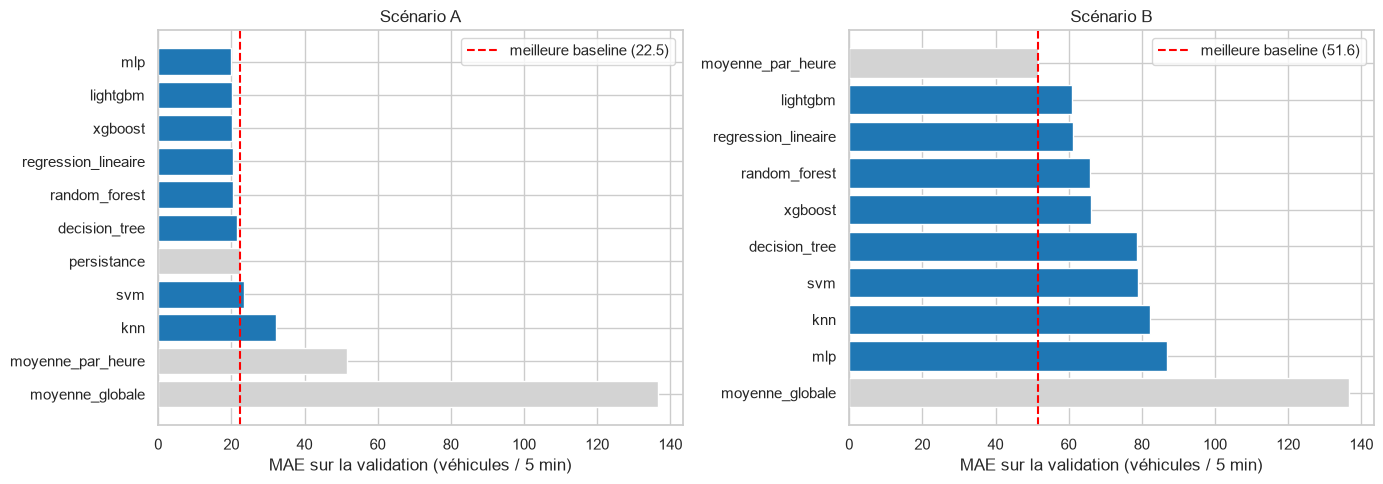

In [44]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, sc in zip(axes, ["A", "B"]):
    t = tableau[tableau["scenario"] == sc].sort_values("MAE", ascending=False)
    couleurs = ["lightgrey" if ty == "baseline" else "tab:blue" for ty in t["type"]]
    ax.barh(t["model"], t["MAE"], color=couleurs)
    meilleure_baseline = t[t["type"] == "baseline"]["MAE"].min()
    ax.axvline(meilleure_baseline, color="red", linestyle="--",
               label=f"meilleure baseline ({meilleure_baseline:.1f})")
    ax.set_title(f"Scénario {sc}")
    ax.set_xlabel("MAE sur la validation (véhicules / 5 min)")
    ax.legend()

plt.tight_layout()
plt.show()

### 9.3 MAE, RMSE et R² par modèle

Les trois métriques du cahier des charges, pour les modèles seuls (sans baselines). Pour MAE et RMSE, plus la barre est courte, mieux c'est ; pour R², plus elle est longue, mieux c'est.

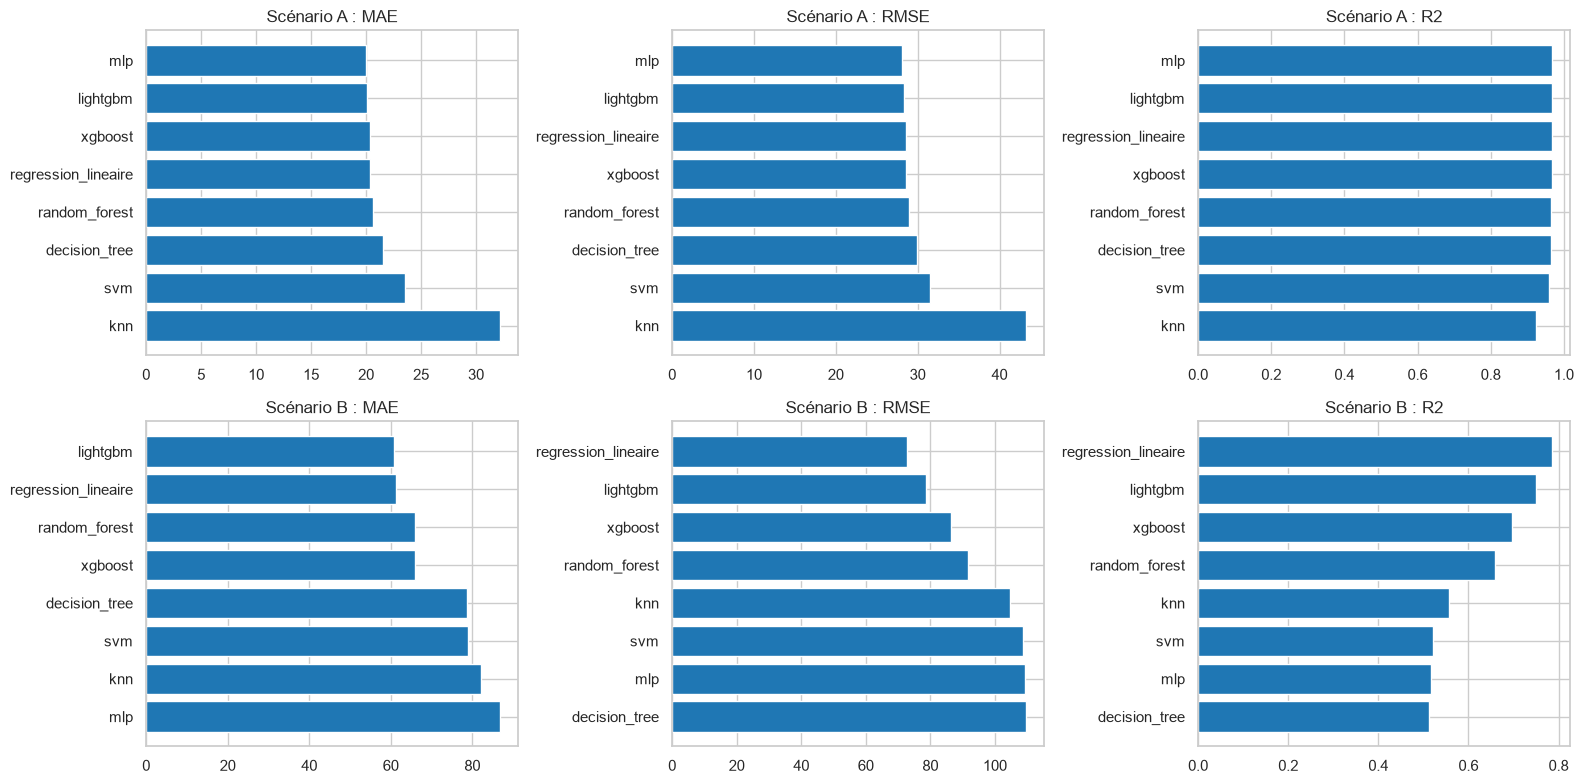

In [45]:
metriques = ["MAE", "RMSE", "R2"]
fig, axes = plt.subplots(2, 3, figsize=(16, 8))

for i, sc in enumerate(["A", "B"]):
    t = tableau[(tableau["scenario"] == sc) & (tableau["type"] == "modèle")]
    for j, m in enumerate(metriques):
        ordre = t.sort_values(m, ascending=(m != "R2"))
        axes[i, j].barh(ordre["model"], ordre[m], color="tab:blue")
        axes[i, j].invert_yaxis()
        axes[i, j].set_title(f"Scénario {sc} : {m}")

plt.tight_layout()
plt.show()

### 9.4 Effet du réglage des hyperparamètres

Comparaison de la MAE de validation avant réglage (hyperparamètres de la section 7) et après (section 8), pour chaque modèle. Un gain positif signifie que le réglage a amélioré la MAE ; un gain négatif signifie qu'elle s'est dégradée sur la validation. La régression linéaire et le SVM n'ont pas été réglés : leur gain est nul.

In [46]:
avant = pd.DataFrame(resultats_defaut)[["model", "scenario", "MAE"]].rename(columns={"MAE": "MAE_avant"})
apres = pd.DataFrame(resultats)[["model", "scenario", "MAE"]].rename(columns={"MAE": "MAE_apres"})

gain = avant.merge(apres, on=["model", "scenario"])
gain["gain (%)"] = (gain["MAE_avant"] - gain["MAE_apres"]) / gain["MAE_avant"] * 100
gain = gain[~gain["model"].isin(noms_baselines)].sort_values(["scenario", "model"]).round(2)
gain.reset_index(drop=True)

,model,scenario,MAE_avant,MAE_apres,gain (%)
0,decision_tree,A,22.96,21.50,6.33
1,knn,A,32.20,32.20,0.00
2,lightgbm,A,19.99,20.08,-0.45
3,mlp,A,20.97,19.96,4.82
4,random_forest,A,20.72,20.59,0.63
5,regression_lineaire,A,20.38,20.38,0.00
6,svm,A,23.51,23.51,0.00
7,xgboost,A,20.05,20.31,-1.31
8,decision_tree,B,78.54,78.73,-0.24
9,knn,B,82.22,82.22,0.00


### 9.5 Observation globale

**Scénario A (avec lags)**

(à compléter) Quels modèles battent la persistance ? De combien ? Les écarts entre les meilleurs modèles sont-ils assez grands pour les départager sur la MAE seule ? Quel modèle est nettement en retrait ?

**Scénario B (sans lags)**

(à compléter) Un modèle bat-il la moyenne par heure ? Quel modèle s'en approche le plus ? Rappel de l'explication : le trafic a baissé entre le train et la validation (COVID-19) et les modèles sans lags ne voient pas ce niveau.

**Temps de calcul**

(à compléter) Quel modèle est le plus lent à entraîner ? Tous les temps d'inférence respectent-ils la limite d'une seconde du cahier des charges ?

**Effet du réglage**

(à compléter) Pour quels modèles le réglage a-t-il été utile ? Pour lesquels n'a-t-il rien changé ou a-t-il dégradé la validation ?

**Limites**

- Tous les chiffres de cette section portent sur la validation, qui est une période de trafic plus bas que le train.
- Le SVM a été entraîné sur un tiers du train.
- Le jeu de test n'a pas encore été utilisé.

In [47]:
pd.set_option("display.width", 250)
pd.set_option("display.max_colwidth", 120)

print("Lignes du train :", len(train))
print("\n=== SCENARIO A ===")
print(tab_A.to_string())
print("\n=== SCENARIO B ===")
print(tab_B.to_string())
print("\n=== EFFET DU REGLAGE ===")
print(gain.to_string(index=False))
print("\n=== HYPERPARAMETRES RETENUS ===")
print(pd.DataFrame(resultats)[["model", "scenario", "best_params"]].to_string(index=False))

Lignes du train : 24374

=== SCENARIO A ===
                    model      type      MAE     RMSE     R2  MAE_train  gap_MAE  cv_std  train_time  infer_time_ms
rang                                                                                                               
1                     mlp    modèle   19.958   28.105  0.968     20.624   -0.666   4.539      14.150          4.320
2                lightgbm    modèle   20.084   28.270  0.968     20.147   -0.063   3.640       2.352          5.274
3                 xgboost    modèle   20.314   28.578  0.967     21.098   -0.784   3.369       4.731          5.082
4     regression_lineaire    modèle   20.376   28.556  0.967     21.598   -1.222   2.926       7.421         19.089
5           random_forest    modèle   20.585   28.960  0.966     20.094    0.492   2.868      61.974         17.081
6           decision_tree    modèle   21.501   29.908  0.964     21.066    0.435   3.094      10.524         13.261
7             persistance  b

### 9.5 Observation globale

Tous les chiffres ci-dessous portent sur la **validation** (25 avril au 13 mai 2020). Le jeu de test n'a pas encore été utilisé.

#### Scénario A (avec lags)

- **Six modèles battent la persistance** (MAE 22,5) : MLP (19,96), LightGBM (20,08), XGBoost (20,31), régression linéaire (20,38), Random Forest (20,59) et Decision Tree (21,50). Le gain va de 4 % (Decision Tree) à 11 % (MLP) sur la MAE. Il est réel mais modeste, car `traffic_flow_lag_1` contient déjà presque toute l'information : le trafic change peu en 5 minutes.
- **Les quatre meilleurs modèles ne se distinguent pas sur la MAE.** Ils tiennent dans un écart de 0,42 véhicule (19,96 à 20,38), très inférieur à la variabilité d'un pli de validation croisée à l'autre (`cv_std` de 2,9 à 4,5). Leur R² est identique (0,967 à 0,968). La performance seule ne permet donc pas de les départager : la sélection devra s'appuyer sur les autres critères de la grille pondérée.
- **La régression linéaire fait presque aussi bien que les modèles complexes** (20,38 contre 19,96 pour le meilleur). Dans ce scénario, la relation entre le débit et ses valeurs passées est surtout linéaire, ce qui est un argument en faveur d'un modèle simple et interprétable.
- **Le SVM (23,51) fait moins bien que la persistance**, et le **KNN (32,20)** est nettement en retrait. Le SVM n'a vu qu'un tiers du train, donc son résultat n'est pas strictement comparable aux autres.
- **Généralisation : aucun surapprentissage chez les meilleurs modèles.** L'écart `gap_MAE` entre validation et train est compris entre −1,2 et +0,5 pour les six premiers. Il est plus élevé pour le SVM (+5,5) et le KNN (+7,9).
- **Stabilité :** le Random Forest (2,87) et la régression linéaire (2,93) sont les plus stables d'un pli à l'autre ; le MLP est le moins stable des six meilleurs (4,54) ; le SVM (12,3) et le KNN (20,4) sont très instables.

#### Scénario B (sans lags)

- **Aucun modèle ne bat la baseline « moyenne par heure »** (MAE 51,6, R² 0,822). Le meilleur est LightGBM (60,90), soit 18 % de plus que la baseline, suivi de la régression linéaire (61,21), du Random Forest (65,85) et de XGBoost (66,01). Le MLP est le moins bon (86,85).
- **Les modèles apprennent le train mais ne transfèrent pas.** Sauf la régression linéaire, tous obtiennent sur le train une MAE de 34 à 64, bien meilleure que celle de la baseline (87,0), mais cet avantage disparaît sur la validation. Les `gap_MAE` sont élevés : de +6,1 (LightGBM) à +40,9 (MLP).
- **La stabilité est très mauvaise** : `cv_std` de 37 à 52 en B, contre 3 à 20 en A. Les erreurs varient énormément d'une période à l'autre.
- **Explication la plus plausible :** sans historique de débit, les modèles ne voient pas le niveau actuel du trafic. Le train contient un trafic plus élevé (moyenne ≈ 416) que la validation (≈ 378) à cause de la baisse liée à la COVID-19 ; les modèles ont donc appris un niveau qui ne correspond plus à la période suivante. Cette explication est cohérente avec tous les indicateurs ci-dessus, mais nous ne l'avons pas testée directement. Une piste serait de fournir au modèle un indicateur du niveau récent du trafic (par exemple le débit moyen de la veille).
- La régression linéaire est un cas à part : son erreur sur le train est élevée (93,8), mais elle est la plus stable (`cv_std` 37,2) et a le meilleur RMSE (72,7) et le meilleur R² (0,786) parmi les modèles.
- **Conséquence pour le projet :** le scénario B, destiné à la page 6 du dashboard, ne permet pas aujourd'hui de faire mieux qu'une moyenne par heure. Il faudra le signaler clairement dans le rapport.

#### Temps de calcul

- Le temps d'entraînement (`train_time`) inclut la validation croisée ou la recherche sur grille ; il mesure donc la procédure complète, pas un simple ajustement.
- **LightGBM est le plus rapide des modèles performants** (2,4 s en A), devant XGBoost (4,7 s) et le MLP (14,2 s). **Le Random Forest est le plus lent** (62 s en A) pour un résultat inférieur à celui des boosting.
- **Tous les temps d'inférence sont très inférieurs à la limite d'une seconde du cahier des charges** : entre 2 et 24 millisecondes pour une prédiction, prétraitement compris. Ce critère ne départage donc pas les modèles.

#### Effet du réglage des hyperparamètres

- **Utile pour le MLP** (−4,8 % de MAE en A, −20,1 % en B) et le Decision Tree en A (−6,3 %), deux modèles sensibles au surapprentissage.
- **Presque sans effet** pour le Random Forest (moins de 1 %) et sans gain pour le KNN, dont la valeur initiale (`n_neighbors=15`) était déjà la meilleure. La régression linéaire et le SVM n'ont pas été réglés.
- **Légèrement défavorable pour les boosting sur la validation** : XGBoost perd 1,3 % en A et 7,0 % en B, LightGBM 0,5 % dans les deux scénarios. Les paramètres choisis par validation croisée sur le train ne sont pas toujours les meilleurs pour la période suivante, ce qui est cohérent avec le changement de régime du trafic.

#### Limites

- Une seule période de validation, plus calme que le train : les écarts de quelques dixièmes de point entre modèles ne sont pas significatifs.
- Le SVM a été entraîné sur un tiers du train et n'a pas été réglé.
- Le scénario B est pénalisé par le changement de régime du trafic de 2020 ; ses résultats ne reflètent pas ce que donnerait une année normale.

#### Conclusion de la comparaison

Dans le scénario A, quatre modèles se détachent (MLP, LightGBM, XGBoost, régression linéaire) avec des performances quasi équivalentes : le choix se jouera sur la grille pondérée de la section 10. Dans le scénario B, la baseline « moyenne par heure » reste la meilleure référence.

## 10. Sélection du meilleur modèle

Objectif : choisir **un modèle de façon objective**, avec la grille pondérée du cahier des charges (section 6.3), appliquée séparément aux scénarios A et B. La sélection porte sur les 8 modèles ; les baselines servent de repère mais ne sont pas candidates.

| Critère | Poids | Indicateur utilisé |
|---|---|---|
| Performance | 40 % | MAE sur la validation |
| Généralisation | 20 % | écart absolu `gap_MAE` entre validation et train |
| Temps d'inférence | 15 % | `infer_time_ms` |
| Robustesse | 15 % | `cv_std` (stabilité en validation croisée temporelle) |
| Interprétabilité | 5 % | note qualitative (voir ci-dessous) |
| Temps d'entraînement | 5 % | `train_time` |

Le cahier des charges regroupe « interprétabilité et temps d'entraînement » en un critère de 10 % ; nous le séparons en deux moitiés égales.

**Choix de méthode :**
- **La performance est mesurée sur la validation, pas sur le test.** Le cahier des charges prévoit le jeu de test pour la performance, mais il doit rester intact jusqu'à l'évaluation finale (section 11), sinon le choix du modèle contaminerait le résultat.
- **Chaque indicateur est ramené entre 0 et 1** par normalisation min-max au sein de chaque scénario : 1 pour le meilleur modèle, 0 pour le moins bon. Le score final est la moyenne pondérée, multipliée par 100.
- **La note d'interprétabilité est un jugement, pas une mesure** : régression linéaire 1,0 (coefficients lisibles), Decision Tree 0,9 (règles lisibles), Random Forest, XGBoost et LightGBM 0,5 (importance des variables disponible), KNN 0,3, SVM 0,2, MLP 0,1 (boîtes noires).
- **Une analyse de sensibilité** vérifie ensuite que le classement ne dépend pas trop des poids.

In [48]:
poids = {"performance": 0.40, "generalisation": 0.20, "inference": 0.15,
         "robustesse": 0.15, "interpretabilite": 0.05, "temps_entrainement": 0.05}
assert abs(sum(poids.values()) - 1) < 1e-9, "Les poids doivent sommer à 1"

interpretabilite = {"regression_lineaire": 1.0, "decision_tree": 0.9, "random_forest": 0.5,
                    "xgboost": 0.5, "lightgbm": 0.5, "knn": 0.3, "svm": 0.2, "mlp": 0.1}

def minmax(s):
    """Ramène une série entre 0 et 1, où 1 = valeur la plus basse (la meilleure)."""
    ecart = s.max() - s.min()
    if ecart == 0:
        return pd.Series(1.0, index=s.index)
    return (s.max() - s) / ecart

def calculer_scores(sc, poids=poids):
    """Score pondéré (0 à 100) des 8 modèles d'un scénario."""
    d = tableau[(tableau["scenario"] == sc) & (tableau["type"] == "modèle")].set_index("model").copy()
    d["s_performance"]        = minmax(d["MAE"])
    d["s_generalisation"]     = minmax(d["gap_MAE"].abs())
    d["s_inference"]          = minmax(d["infer_time_ms"])
    d["s_robustesse"]         = minmax(d["cv_std"])
    d["s_interpretabilite"]   = pd.Series(interpretabilite)
    d["s_temps_entrainement"] = minmax(d["train_time"])
    d["score"] = 100 * (poids["performance"] * d["s_performance"]
                        + poids["generalisation"] * d["s_generalisation"]
                        + poids["inference"] * d["s_inference"]
                        + poids["robustesse"] * d["s_robustesse"]
                        + poids["interpretabilite"] * d["s_interpretabilite"]
                        + poids["temps_entrainement"] * d["s_temps_entrainement"])
    d = d.sort_values("score", ascending=False)
    d.insert(0, "rang", range(1, len(d) + 1))
    return d

print("Poids :", poids)

Poids : {'performance': 0.4, 'generalisation': 0.2, 'inference': 0.15, 'robustesse': 0.15, 'interpretabilite': 0.05, 'temps_entrainement': 0.05}


### 10.1 Scores pondérés

Les colonnes `s_...` sont les sous-scores de chaque critère (1 = meilleur, 0 = moins bon). `score` est le résultat final sur 100.

In [49]:
scores_A, scores_B = calculer_scores("A"), calculer_scores("B")
sous_scores = ["s_performance", "s_generalisation", "s_inference",
               "s_robustesse", "s_interpretabilite", "s_temps_entrainement"]

print("Scénario A (avec lags)")
display(scores_A[["rang", "MAE"] + sous_scores + ["score"]].round(3))
print("Scénario B (sans lags)")
display(scores_B[["rang", "MAE"] + sous_scores + ["score"]].round(3))

Scénario A (avec lags)


,rang,MAE,s_performance,s_generalisation,s_inference,s_robustesse,s_interpretabilite,s_temps_entrainement,score
model,,,,,,,,,
lightgbm,1,20.084,0.990,1.000,0.935,0.956,0.5,1.000,95.463
xgboost,2,20.314,0.971,0.909,0.948,0.971,0.5,0.960,93.108
mlp,3,19.958,1.000,0.924,1.000,0.905,0.1,0.802,91.552
decision_tree,4,21.501,0.874,0.953,0.395,0.987,0.9,0.863,83.558
regression_lineaire,5,20.376,0.966,0.853,0.000,0.997,1.0,0.915,80.220
random_forest,6,20.585,0.949,0.946,0.136,1.000,0.5,0.000,76.404
svm,7,23.514,0.710,0.313,0.582,0.464,0.2,0.471,53.676
knn,8,32.203,0.000,0.000,0.773,0.000,0.3,0.992,18.060


Scénario B (sans lags)


,rang,MAE,s_performance,s_generalisation,s_inference,s_robustesse,s_interpretabilite,s_temps_entrainement,score
model,,,,,,,,,
lightgbm,1,60.899,1.000,1.000,0.976,0.003,0.5,0.984,82.101
regression_lineaire,2,61.210,0.988,0.237,0.090,1.000,1.0,0.890,70.061
xgboost,3,66.007,0.803,0.609,0.979,0.063,0.5,0.944,67.148
decision_tree,4,78.726,0.313,0.755,0.875,0.030,0.9,1.000,50.685
knn,5,82.218,0.178,0.529,0.750,0.557,0.3,0.974,43.683
svm,6,78.923,0.305,0.313,0.639,0.785,0.2,0.305,42.361
random_forest,7,65.845,0.809,0.257,0.000,0.000,0.5,0.273,41.385
mlp,8,86.845,0.000,0.000,1.000,0.194,0.1,0.000,18.414


### 10.2 Analyse de sensibilité aux poids

Les poids de la grille sont une convention : il faut donc vérifier que le classement ne change pas dès qu'on les modifie un peu. Nous recalculons les scores avec trois pondérations alternatives et nous regardons les trois premiers modèles.

| Variante | Idée |
|---|---|
| Sans temps d'inférence | les écarts de quelques millisecondes sont en partie du bruit de mesure, et tous les modèles restent très sous la limite d'une seconde |
| Performance renforcée | la MAE pèse 60 % |
| Robustesse renforcée | la stabilité en validation croisée pèse 30 % |

In [50]:
variantes = {
    "Pondération du cahier des charges": poids,
    "Sans temps d'inférence": {"performance": 0.40/0.85, "generalisation": 0.20/0.85,
                               "inference": 0.0, "robustesse": 0.15/0.85,
                               "interpretabilite": 0.05/0.85, "temps_entrainement": 0.05/0.85},
    "Performance renforcée (60 %)": {"performance": 0.60, "generalisation": 0.10, "inference": 0.10,
                                     "robustesse": 0.10, "interpretabilite": 0.05, "temps_entrainement": 0.05},
    "Robustesse renforcée": {"performance": 0.25, "generalisation": 0.25, "inference": 0.10,
                             "robustesse": 0.30, "interpretabilite": 0.05, "temps_entrainement": 0.05},
}

sensibilite = {}
for nom, w in variantes.items():
    sensibilite[nom] = [", ".join(calculer_scores(sc, w).index[:3]) for sc in ["A", "B"]]

pd.DataFrame(sensibilite, index=["Scénario A (top 3)", "Scénario B (top 3)"]).T

,Scénario A (top 3),Scénario B (top 3)
Pondération du cahier des charges,"lightgbm, xgboost, mlp","lightgbm, regression_lineaire, xgboost"
Sans temps d'inférence,"lightgbm, regression_lineaire, xgboost","regression_lineaire, lightgbm, xgboost"
Performance renforcée (60 %),"lightgbm, xgboost, mlp","lightgbm, regression_lineaire, xgboost"
Robustesse renforcée,"lightgbm, xgboost, mlp","regression_lineaire, lightgbm, xgboost"


### 10.3 Graphique des scores

Score final sur 100 de chaque modèle. Le meilleur modèle de chaque scénario est en vert.

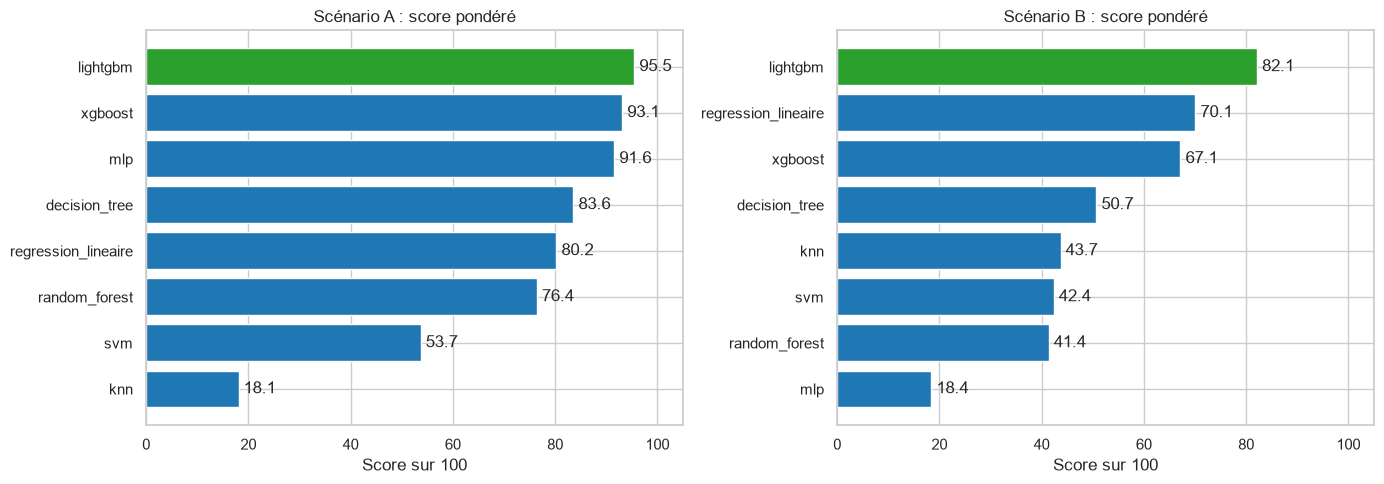

In [51]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, sc, sd in zip(axes, ["A", "B"], [scores_A, scores_B]):
    t = sd.sort_values("score")
    couleurs = ["tab:green" if m == sd.index[0] else "tab:blue" for m in t.index]
    ax.barh(t.index, t["score"], color=couleurs)
    for i, v in enumerate(t["score"]):
        ax.text(v + 1, i, f"{v:.1f}", va="center")
    ax.set_title(f"Scénario {sc} : score pondéré")
    ax.set_xlabel("Score sur 100")
    ax.set_xlim(0, 105)

plt.tight_layout()
plt.show()

### 10.4 Modèle retenu

Nous retenons, dans chaque scénario, le modèle qui a obtenu le meilleur score pondéré. Le tableau résume ses performances et les compare à la meilleure baseline du scénario (persistance en A, moyenne par heure en B).

In [52]:
meilleur = {"A": scores_A.index[0], "B": scores_B.index[0]}
baseline_ref = {"A": "persistance", "B": "moyenne_par_heure"}
scores = {"A": scores_A, "B": scores_B}

lignes = []
for sc in ["A", "B"]:
    m = tableau[(tableau["scenario"] == sc) & (tableau["model"] == meilleur[sc])].iloc[0]
    b = tableau[(tableau["scenario"] == sc) & (tableau["model"] == baseline_ref[sc])].iloc[0]
    lignes.append({
        "scénario": sc,
        "modèle retenu": meilleur[sc],
        "score": round(scores[sc].loc[meilleur[sc], "score"], 1),
        "MAE": round(m["MAE"], 2),
        "R2": round(m["R2"], 3),
        "gap_MAE": round(m["gap_MAE"], 2),
        "cv_std": round(m["cv_std"], 2),
        "baseline de référence": baseline_ref[sc],
        "MAE baseline": round(b["MAE"], 2),
        "écart vs baseline (%)": round((m["MAE"] - b["MAE"]) / b["MAE"] * 100, 1),
        "hyperparamètres": m["best_params"],
    })

retenus = pd.DataFrame(lignes).set_index("scénario")
retenus.T

scénario,A,B
modèle retenu,lightgbm,lightgbm
score,95.5,82.1
MAE,20.08,60.9
R2,0.968,0.75
gap_MAE,-0.06,6.1
cv_std,3.64,51.68
baseline de référence,persistance,moyenne_par_heure
MAE baseline,22.47,51.61
écart vs baseline (%),-10.6,18.0
hyperparamètres,"{'modele__learning_rate': 0.05, 'modele__max_depth': 5, 'modele__n_estimators': 100}","{'modele__learning_rate': 0.05, 'modele__max_depth': 5, 'modele__n_estimators': 300}"


### 10.5 Conclusion de la sélection

**Scénario A : LightGBM est retenu (score 95,5 sur 100).**

- Il bat la baseline de persistance de 10,6 % sur la MAE (20,08 contre 22,47 véhicules par 5 minutes) et son R² est de 0,968.
- Il n'a pas la MAE la plus basse : le MLP fait légèrement mieux (19,96), mais l'écart de 0,13 véhicule est très inférieur à la variabilité d'un pli de validation croisée à l'autre (`cv_std` de 3,6 à 4,5). Sur la performance seule, ces modèles sont indiscernables.
- Il l'emporte sur les autres critères : l'écart entre validation et train est quasi nul (−0,06, donc aucun surapprentissage), il est stable en validation croisée (`cv_std` 3,64), il est le plus rapide à entraîner (2,4 s) et il garde une interprétabilité correcte grâce à l'importance des variables, ce que le MLP n'offre pas.
- Son avance sur XGBoost (95,5 contre 93,1) est faible. Il reste premier dans les trois variantes de pondération testées au 10.2, alors que le deuxième rang change selon la pondération.

**Scénario B : LightGBM est retenu par la grille (score 82,1), mais avec de fortes réserves.**

- Il n'a pas battu la baseline « moyenne par heure » : sa MAE est de 60,90 contre 51,62, soit 18 % de plus. Dans ce scénario, un modèle d'apprentissage n'apporte donc aucun gain sur une règle simple.
- Son classement est fragile. La régression linéaire le suit de très près sur la MAE (61,21, soit 0,31 de plus) et prend la première place dans deux des quatre pondérations testées. Elle est plus stable (`cv_std` 37,2 contre 51,7), a un meilleur RMSE (72,7 contre 78,6) et est bien plus interprétable.
- La stabilité de tous les modèles de ce scénario est mauvaise (`cv_std` de 37 à 52), ce qui est cohérent avec l'explication proposée à la section 9 : sans historique de débit, les modèles ne voient pas le niveau du trafic, qui a baissé entre le train et la validation à cause de la COVID-19. Nous n'avons pas testé cette explication directement.

**Décision pour le projet.**

- Le **modèle principal du projet est LightGBM en scénario A**. C'est lui qui alimentera le module de décision des feux et la validation par simulation, car la régulation en temps réel dispose de l'historique récent du débit.
- Le scénario B sera conservé pour la page de prédiction interactive du dashboard avec LightGBM, tel que désigné par la grille, mais ses limites seront indiquées dans le rapport et dans l'interface : ses prédictions sont moins fiables qu'une simple moyenne par heure.

**Limites de cette sélection.**

- La performance est mesurée sur la validation, qui est une période plus calme que le train, et non sur le test.
- Les temps d'inférence (2 à 24 ms) varient d'une exécution à l'autre et incluent le prétraitement : leurs écarts relèvent en partie du bruit de mesure. Retirer ce critère ne change pas le vainqueur en A et le laisse parmi les trois premiers en B.
- La note d'interprétabilité est un jugement, pas une mesure.
- Le SVM a été entraîné sur un tiers du train et n'a pas été réglé ; il n'aurait de toute façon pas pu rivaliser en A (MAE 23,5).

Le jeu de test n'a toujours pas été utilisé. La section suivante l'utilise une seule fois pour vérifier les performances des modèles retenus.

## 11. Évaluation finale sur le jeu de test

Objectif : mesurer la performance réelle des modèles retenus sur des données qu'ils n'ont jamais vues. **Le jeu de test n'est utilisé qu'ici, une seule fois, et le choix du modèle ne sera pas remis en cause après ce résultat.**

Méthode :
- Nous reconstruisons LightGBM avec les hyperparamètres retenus à la section 8 et nous l'entraînons sur le **train seul**, comme lors de la comparaison.
- Nous l'évaluons sur la validation (pour mémoire) et sur le test.
- Nous évaluons aussi, à titre de référence, la meilleure baseline de chaque scénario : persistance en A, moyenne par heure en B.
- Les écarts entre validation et test indiquent si les performances se confirment sur une période nouvelle.

Le test couvre du 13 au 31 mai 2020, avec un débit moyen d'environ 406 véhicules par 5 minutes, plus proche de celui du train (≈ 416) que celui de la validation (≈ 378).

In [53]:
import ast
from lightgbm import LGBMRegressor

test = ajouter_variables_cycliques(test)
y_test = test["traffic_flow"]

def reconstruire(sc):
    """Reconstruit le LightGBM retenu avec ses hyperparamètres et l'entraîne sur le train."""
    assert meilleur[sc] == "lightgbm", "Cette cellule suppose que LightGBM est le modèle retenu"
    params_txt = retenus.loc[sc, "hyperparamètres"]
    params = {k.replace("modele__", ""): v for k, v in ast.literal_eval(params_txt).items()}
    feats = features_A if sc == "A" else features_B
    num = num_A if sc == "A" else num_B
    modele = LGBMRegressor(random_state=SEED, n_jobs=1, verbose=-1, **params)
    pipe = faire_pipeline(modele, num, normaliser=False)
    pipe.fit(train[feats], y_train)
    return pipe, feats

lignes, predictions_test = [], {}
for sc in ["A", "B"]:
    pipe, feats = reconstruire(sc)
    pred_val, pred_test = pipe.predict(val[feats]), pipe.predict(test[feats])
    predictions_test[sc] = pred_test
    m_val, m_test = evaluer(y_val, pred_val), evaluer(y_test, pred_test)
    lignes.append({"scénario": sc, "modèle": "lightgbm (retenu)",
                   "MAE val": m_val["MAE"], "MAE test": m_test["MAE"],
                   "RMSE test": m_test["RMSE"], "R2 val": m_val["R2"], "R2 test": m_test["R2"]})

    # Baseline de référence du scénario (calculée sur le train uniquement)
    if sc == "A":
        nom_b, b_val, b_test = "persistance", val["traffic_flow_lag_1"].values, test["traffic_flow_lag_1"].values
    else:
        nom_b, b_val, b_test = "moyenne_par_heure", pred_moyenne_par_heure(val), pred_moyenne_par_heure(test)
    mb_val, mb_test = evaluer(y_val, b_val), evaluer(y_test, b_test)
    lignes.append({"scénario": sc, "modèle": nom_b + " (baseline)",
                   "MAE val": mb_val["MAE"], "MAE test": mb_test["MAE"],
                   "RMSE test": mb_test["RMSE"], "R2 val": mb_val["R2"], "R2 test": mb_test["R2"]})

final = pd.DataFrame(lignes).set_index(["scénario", "modèle"])
final.round(3)

MAE val  MAE test  RMSE test  R2 val  R2 test
scénario modèle                                                                     
A        lightgbm (retenu)              20.084    21.025     29.149   0.968    0.972
         persistance (baseline)         22.469    23.009     31.619   0.960    0.967
B        lightgbm (retenu)              60.899    56.064     71.003   0.750    0.832
         moyenne_par_heure (baseline)   51.615    45.381     60.730   0.822    0.877

### 11.1 Qualité des prédictions du modèle retenu (scénario A)

Quatre vues du modèle de référence du projet sur le jeu de test : valeurs réelles et prédites sur une semaine, nuage de points réel contre prédit, distribution des résidus (réel moins prédit), et résidus dans le temps.

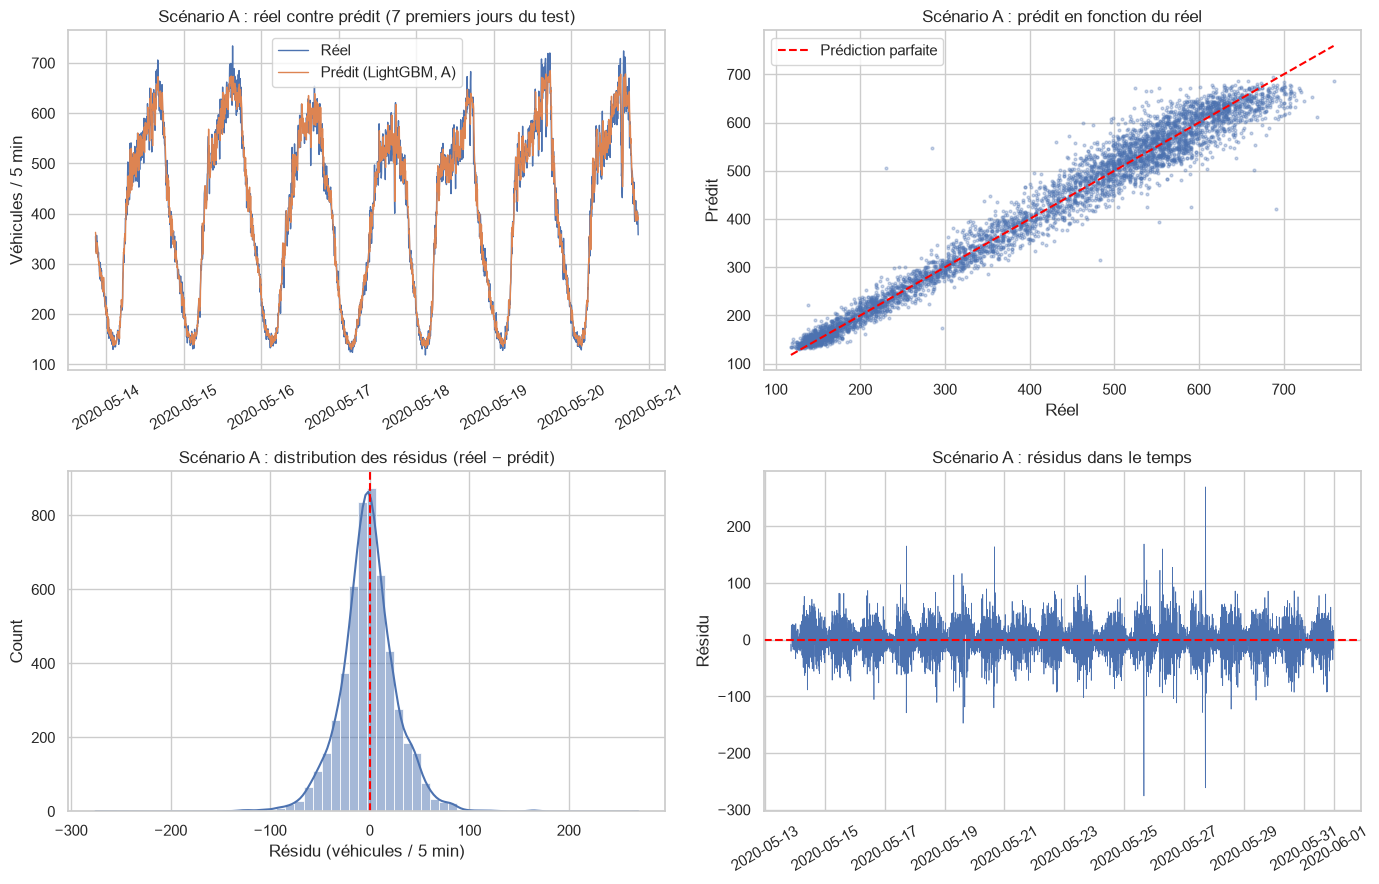

Résidus A : moyenne -1.24 | écart-type 29.12 | erreur absolue maximale 275.6


In [54]:
pred_test_A = predictions_test["A"]
res_A = y_test.values - pred_test_A
semaine = test["datetime"] < test["datetime"].min() + pd.Timedelta(days=7)

fig, axes = plt.subplots(2, 2, figsize=(14, 9))

axes[0, 0].plot(test.loc[semaine, "datetime"], y_test[semaine], label="Réel", linewidth=1)
axes[0, 0].plot(test.loc[semaine, "datetime"], pred_test_A[semaine], label="Prédit (LightGBM, A)", linewidth=1)
axes[0, 0].set_title("Scénario A : réel contre prédit (7 premiers jours du test)")
axes[0, 0].set_ylabel("Véhicules / 5 min")
axes[0, 0].legend()
axes[0, 0].tick_params(axis="x", rotation=30)

axes[0, 1].scatter(y_test, pred_test_A, s=4, alpha=0.3)
lim = [y_test.min(), y_test.max()]
axes[0, 1].plot(lim, lim, color="red", linestyle="--", label="Prédiction parfaite")
axes[0, 1].set_title("Scénario A : prédit en fonction du réel")
axes[0, 1].set_xlabel("Réel")
axes[0, 1].set_ylabel("Prédit")
axes[0, 1].legend()

sns.histplot(res_A, bins=60, kde=True, ax=axes[1, 0])
axes[1, 0].axvline(0, color="red", linestyle="--")
axes[1, 0].set_title("Scénario A : distribution des résidus (réel − prédit)")
axes[1, 0].set_xlabel("Résidu (véhicules / 5 min)")

axes[1, 1].plot(test["datetime"], res_A, linewidth=0.5)
axes[1, 1].axhline(0, color="red", linestyle="--")
axes[1, 1].set_title("Scénario A : résidus dans le temps")
axes[1, 1].set_ylabel("Résidu")
axes[1, 1].tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()

print("Résidus A : moyenne", res_A.mean().round(2), "| écart-type", res_A.std().round(2),
      "| erreur absolue maximale", np.abs(res_A).max().round(1))

### 11.2 Conclusion de l'évaluation finale

**Scénario A : les performances se confirment sur le test.**

- LightGBM obtient une MAE de **21,03** véhicules par 5 minutes sur le test, contre 23,01 pour la persistance : un gain de **8,6 %** (RMSE 29,15 contre 31,62, R² de 0,972 contre 0,967). Le gain était de 10,6 % sur la validation ; il est un peu plus faible, mais du même ordre.
- L'erreur moyenne représente environ **5 % du débit moyen** de la période (≈ 406 véhicules par 5 minutes).
- Les résidus sont centrés sur zéro (moyenne ≈ −1,2) : le modèle ne sur-estime ni ne sous-estime systématiquement le trafic. Leur écart-type est d'environ 29 véhicules, et l'erreur maximale atteint environ 276 véhicules : quelques erreurs ponctuelles sont très grandes, sans que nous ayons cherché à les expliquer.
- La MAE passe de 20,08 (validation) à 21,03 (test), tandis que celle de la persistance passe de 22,47 à 23,01. Les deux se dégradent de la même façon, ce qui indique que le test est un peu plus difficile et non que le modèle surapprend.

**Scénario B : le modèle reste moins bon que la baseline.**

- LightGBM obtient une MAE de **56,06** sur le test, contre 45,38 pour la moyenne par heure : **23,5 % de plus**, un écart plus marqué que sur la validation (18 %). Son R² est de 0,832 contre 0,877 pour la baseline.
- En valeur absolue, les deux méthodes font mieux sur le test que sur la validation (par exemple 45,4 contre 51,6 pour la baseline). Ce résultat est cohérent avec l'idée que le test, dont le débit moyen est plus proche de celui du train, correspond à un régime de trafic plus facile pour des modèles qui ne voient pas le niveau actuel du trafic. Nous n'avons pas vérifié cette explication directement.
- Le constat de la section 10 est confirmé : sans historique de débit, un modèle d'apprentissage n'apporte pas de gain sur une moyenne par heure.

**Décision.** Le choix des modèles n'est pas modifié par ces résultats : le modèle principal du projet est LightGBM en scénario A.

**Limites.**

- Le test ne couvre que 18 jours, dans une période de reprise partielle du trafic après la COVID-19. Ces scores ne représentent pas une année normale.
- Le scénario A prédit le débit des 5 prochaines minutes à partir du débit réel des 5 et 15 minutes précédentes. Nous n'avons pas évalué de prévision à plus long terme (15 minutes, 1 heure), qui serait plus difficile.
- Un gain de 8,6 % sur la persistance est réel mais modeste : la valeur du modèle dépendra de la façon dont le module de décision des feux utilise la prédiction, ce que la simulation mesurera.

## 12. Interprétabilité et sauvegarde du modèle

Objectif : comprendre quelles variables influencent le modèle (exigence d'interprétabilité du cahier des charges), puis sauvegarder le modèle final et les résultats pour les autres membres de l'équipe : simulation, module de décision et dashboard.

### 12.1 Importance des variables

Méthode : **importance par permutation**. Pour chaque variable, nous mélangeons au hasard ses valeurs sur la validation et nous mesurons de combien la MAE augmente. Plus la hausse est grande, plus le modèle dépend de cette variable. Cette méthode fonctionne quel que soit le modèle et s'applique ici aux variables d'origine : `weather_condition` est traitée comme une seule variable, et non en plusieurs colonnes One-Hot.

Elle est calculée sur la validation (5 répétitions), pas sur le test, pour ne pas toucher à ce jeu une seconde fois.

Scénario A


,variable,hausse_MAE,ecart_type
0,traffic_flow_lag_1,108.502,1.532
1,traffic_flow_lag_3,30.918,0.464
2,hour_cos,1.484,0.023
3,hour_sin,0.487,0.035
4,minute_cos,0.466,0.048
5,minute_sin,0.171,0.019
6,is_weekend,0.033,0.006
7,holidays,0.018,0.005
8,wind_speed_kmh,0.007,0.003
9,weekday_sin,0.002,0.002


Scénario B


,variable,hausse_MAE,ecart_type
0,hour_cos,109.524,2.177
1,hour_sin,54.158,0.694
2,temp_celsius,6.529,0.607
3,wind_speed_kmh,5.368,0.130
4,is_weekend,4.309,0.214
5,weekday_cos,1.648,0.345
6,minute_sin,1.509,0.249
7,holidays,1.022,0.204
8,minute_cos,0.523,0.086
9,weather_condition,0.024,0.097


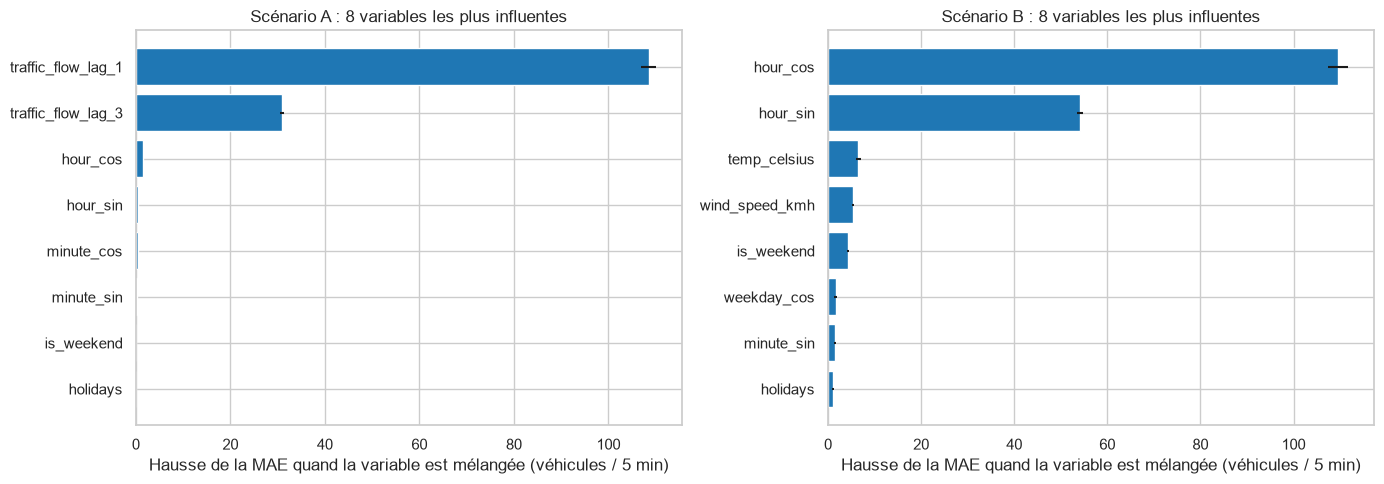

In [55]:
from sklearn.inspection import permutation_importance

importances = {}
for sc in ["A", "B"]:
    pipe, feats = reconstruire(sc)
    r = permutation_importance(pipe, val[feats], y_val, scoring="neg_mean_absolute_error",
                               n_repeats=5, random_state=SEED, n_jobs=1)
    importances[sc] = pd.DataFrame({"variable": feats, "hausse_MAE": r.importances_mean,
                                    "ecart_type": r.importances_std}).sort_values("hausse_MAE", ascending=False)

for sc in ["A", "B"]:
    print(f"Scénario {sc}")
    display(importances[sc].round(3).reset_index(drop=True))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, sc in zip(axes, ["A", "B"]):
    t = importances[sc].head(8).iloc[::-1]
    ax.barh(t["variable"], t["hausse_MAE"], xerr=t["ecart_type"], color="tab:blue")
    ax.set_title(f"Scénario {sc} : 8 variables les plus influentes")
    ax.set_xlabel("Hausse de la MAE quand la variable est mélangée (véhicules / 5 min)")
plt.tight_layout()
plt.show()

**Observation :**

- **Scénario A** : le modèle repose presque entièrement sur les deux décalages de débit. Mélanger `traffic_flow_lag_1` fait grimper la MAE d'environ 108 véhicules, `traffic_flow_lag_3` d'environ 31. Les autres variables pèsent très peu : la plus utile, `hour_cos`, ajoute environ 1,5, et la météo (température, vent, précipitations, état du ciel) est négligeable, avec une hausse de MAE inférieure à 0,01. Cela confirme que le trafic des 5 prochaines minutes se déduit surtout du trafic des minutes précédentes.
- **Scénario B** : sans décalages, le modèle s'appuie sur l'**heure de la journée** (`hour_cos` : 109,5 ; `hour_sin` : 54,2), qui domine largement. Viennent ensuite la température (6,5), le vent (5,4) et le week-end (4,3). L'état du ciel et les précipitations ne contribuent pas.
- **Prudence sur la météo en B :** la température et le vent apparaissent comme un peu influents, mais la période est courte (quatre mois) et les conditions météo sont mélangées avec le changement de trafic lié à la COVID-19 (section 3.6). Cette influence peut refléter un effet de période plutôt qu'un effet réel de la météo sur le trafic, et nous n'avons pas pu le distinguer.
- Une valeur légèrement négative (par exemple `weekday_sin` en B, ≈ −1,6) signifie que mélanger la variable a un peu amélioré le résultat : la variable ne sert à rien pour le modèle, et la valeur est du bruit.
- Conséquence pour la page 6 du dashboard : l'utilisateur qui saisira une date, une heure et une météo agira surtout sur l'heure et le week-end ; la météo aura un effet faible.

### 12.2 Sauvegarde des modèles finaux

Nous sauvegardons les deux modèles retenus (scénarios A et B) avec `joblib`, **pipeline de prétraitement incluse** : le fichier contient la normalisation, l'encodage One-Hot et LightGBM. Les autres membres de l'équipe (simulation, dashboard) n'ont donc qu'à charger le fichier et lui passer un tableau avec les bonnes colonnes.

Les modèles sont ceux entraînés sur le **train seul**, c'est-à-dire ceux qui ont été évalués à la section 11. Aucune nouvelle donnée n'a été ajoutée.

Nous ajoutons un fichier `model_info.json` qui décrit, pour chaque modèle, les colonnes d'entrée attendues, les hyperparamètres, les performances et les versions des bibliothèques (un modèle sauvegardé ne se recharge de façon fiable qu'avec les mêmes versions).

Nous vérifions enfin que le modèle rechargé prédit exactement comme l'original et nous mesurons son temps d'inférence pour une ligne (objectif du cahier des charges : moins d'une seconde).

In [56]:
import joblib, json, sklearn, lightgbm
from pathlib import Path

dossier_modeles, dossier_resultats = Path("../models"), Path("../results")
dossier_modeles.mkdir(exist_ok=True)
dossier_resultats.mkdir(exist_ok=True)

infos = {}
for sc in ["A", "B"]:
    pipe, feats = reconstruire(sc)
    chemin = dossier_modeles / f"best_model_{sc}.pkl"
    joblib.dump(pipe, chemin)

    # Vérification : le modèle rechargé prédit exactement comme l'original (sur la validation)
    recharge = joblib.load(chemin)
    identiques = np.allclose(pipe.predict(val[feats]), recharge.predict(val[feats]))

    # Temps d'inférence pour une seule ligne, depuis le modèle rechargé
    une_ligne = val[feats].iloc[[0]]
    t0 = time.perf_counter()
    for _ in range(50):
        recharge.predict(une_ligne)
    ms = (time.perf_counter() - t0) / 50 * 1000

    params = {k.replace("modele__", ""): v
              for k, v in ast.literal_eval(retenus.loc[sc, "hyperparamètres"]).items()}
    infos[sc] = {
        "modele": "lightgbm", "fichier": chemin.name,
        "variables_entree": feats, "hyperparametres": params,
        "MAE_validation": round(float(final.loc[(sc, "lightgbm (retenu)"), "MAE val"]), 3),
        "MAE_test": round(float(final.loc[(sc, "lightgbm (retenu)"), "MAE test"]), 3),
        "R2_test": round(float(final.loc[(sc, "lightgbm (retenu)"), "R2 test"]), 3),
    }
    print(f"Scénario {sc} : {chemin.name} | {chemin.stat().st_size / 1024:.0f} Ko | "
          f"prédictions identiques après rechargement : {identiques} | inférence : {ms:.1f} ms")

infos["versions"] = {"python": __import__("sys").version.split()[0],
                     "scikit-learn": sklearn.__version__, "lightgbm": lightgbm.__version__,
                     "pandas": pd.__version__, "numpy": np.__version__}
infos["graine_aleatoire"] = SEED

with open(dossier_modeles / "model_info.json", "w", encoding="utf-8") as f:
    json.dump(infos, f, indent=2, ensure_ascii=False)
print("model_info.json écrit")

Scénario A : best_model_A.pkl | 271 Ko | prédictions identiques après rechargement : True | inférence : 9.2 ms
Scénario B : best_model_B.pkl | 693 Ko | prédictions identiques après rechargement : True | inférence : 8.7 ms
model_info.json écrit


### 12.3 Export des résultats pour l'équipe

Nous écrivons dans `results/` les fichiers dont les autres membres ont besoin :

| Fichier | Contenu | Utilisateur |
|---|---|---|
| `metrics.csv` | tous les modèles et baselines des deux scénarios, avec le score pondéré (métriques sur la **validation**) | pages 3 du dashboard |
| `metrics_test.csv` | résultats finaux des modèles retenus sur le **test** | pages 3 et 4 du dashboard |
| `predictions_lightgbm_A.csv` et `_B.csv` | date, valeur réelle et valeur prédite sur le test | page 4 du dashboard (réel contre prédit, résidus) |

In [57]:
scores_tous = pd.concat([scores_A.assign(scenario="A"), scores_B.assign(scenario="B")])
scores_tous = scores_tous.reset_index()[["model", "scenario", "score"]] \
                         .rename(columns={"score": "score_pondere"})

metrics = tableau.merge(scores_tous, on=["model", "scenario"], how="left")
ordre = ["model", "scenario", "type", "MAE", "RMSE", "R2", "MAE_train", "gap_MAE",
         "cv_std", "train_time", "infer_time_ms", "score_pondere", "best_params"]
metrics[ordre].to_csv(dossier_resultats / "metrics.csv", index=False)

final.reset_index().to_csv(dossier_resultats / "metrics_test.csv", index=False)

for sc in ["A", "B"]:
    pd.DataFrame({"datetime": test["datetime"], "y_true": y_test.values,
                  "y_pred": predictions_test[sc]}).to_csv(
        dossier_resultats / f"predictions_lightgbm_{sc}.csv", index=False)

for nom in ["metrics.csv", "metrics_test.csv", "predictions_lightgbm_A.csv", "predictions_lightgbm_B.csv"]:
    print(nom, pd.read_csv(dossier_resultats / nom).shape)

metrics.csv (21, 13)
metrics_test.csv (4, 7)
predictions_lightgbm_A.csv (5223, 3)
predictions_lightgbm_B.csv (5223, 3)


## 13. Conclusion

### Démarche

Nous avons comparé **8 modèles** (régression linéaire, Decision Tree, Random Forest, KNN, SVM, XGBoost, LightGBM, MLP) à **3 baselines** (persistance, moyenne par heure, moyenne globale), dans **deux scénarios** :

- **Scénario A** (avec le débit des 5 et 15 minutes précédentes), destiné à la régulation des feux en temps réel ;
- **Scénario B** (calendrier et météo uniquement), destiné à la page de prédiction interactive du dashboard.

La méthode est restée la même pour tous : découpage chronologique 70 / 15 / 15, pipeline de prétraitement ajustée sur le train seul, réglage par validation croisée temporelle, comparaison sur la validation, sélection par la grille pondérée du cahier des charges (avec analyse de sensibilité aux poids), puis évaluation unique sur le test.

### Résultats

| | Scénario A | Scénario B |
|---|---|---|
| Modèle retenu | LightGBM (score 95,5) | LightGBM (score 82,1) |
| MAE validation | 20,08 | 60,90 |
| MAE test | 21,03 | 56,06 |
| R² test | 0,972 | 0,832 |
| Meilleure baseline | persistance | moyenne par heure |
| MAE test de la baseline | 23,01 | 45,38 |
| Écart du modèle à la baseline (test) | −8,6 % (meilleur) | +23,5 % (moins bon) |

### Ce que nous retenons

1. **Scénario A : un modèle utile, mais un gain modeste.** LightGBM bat la persistance de 8,6 % sur le test, avec une erreur moyenne d'environ 5 % du débit. Quatre modèles (MLP, LightGBM, XGBoost, régression linéaire) sont indiscernables sur la performance seule ; LightGBM a été choisi grâce à sa généralisation, sa stabilité, sa rapidité d'entraînement et son interprétabilité.
2. **Le trafic des 5 prochaines minutes se déduit surtout du trafic des minutes précédentes.** Les deux décalages de débit expliquent presque toute la performance du scénario A ; la météo y est négligeable.
3. **Scénario B : aucun modèle ne bat la moyenne par heure.** Sans historique de débit, l'apprentissage n'apporte pas de gain, et la stabilité est mauvaise. Nous attribuons cela au changement de régime du trafic lié à la COVID-19 (le débit moyen passe d'environ 500 en février à environ 333 en avril), mais nous ne l'avons pas démontré directement.
4. **Le réglage des hyperparamètres a été utile pour le MLP et le Decision Tree**, presque neutre pour les autres, et légèrement défavorable sur la validation pour XGBoost et LightGBM.
5. **Le temps d'inférence n'est pas un obstacle** : de 2 à 24 millisecondes pour une prédiction, prétraitement compris, très en dessous de la limite d'une seconde.

### Modèle livré au reste du projet

- **Modèle principal : LightGBM, scénario A** (`models/best_model_A.pkl`), pour le module de décision des feux et la simulation. Il prédit le débit des 5 prochaines minutes ; il lui faut donc le débit mesuré 5 et 15 minutes plus tôt.
- **Modèle secondaire : LightGBM, scénario B** (`models/best_model_B.pkl`), pour la page 6 du dashboard. Ses prédictions sont moins fiables qu'une simple moyenne par heure, et cette limite doit apparaître dans le rapport et dans l'interface.

### Limites

- Quatre mois de données seulement (février à mai 2020), sur un seul tronçon, avec un changement de régime du trafic : les scores ne reflètent pas une année normale.
- Un seul jeu de test de 18 jours.
- Seule la prévision à 5 minutes a été évaluée, pas des horizons plus longs.
- Le SVM a été entraîné sur un tiers du train et n'a pas été réglé.
- Les temps d'inférence varient d'une exécution à l'autre ; la note d'interprétabilité est un jugement.

### Pistes d'amélioration

- Pour le scénario B, fournir au modèle un indicateur du niveau récent du trafic (par exemple le débit moyen de la veille), afin qu'il puisse suivre le changement de régime.
- Évaluer des horizons de prédiction plus longs (15 minutes, 1 heure), plus proches des besoins d'une régulation anticipée.
- Réentraîner le modèle final sur le train et la validation réunis, pour intégrer des données plus récentes avant un usage réel.
- Entraîner le SVM sur le train complet, si le temps de calcul le permet.

### Fichiers produits

| Fichier | Contenu |
|---|---|
| `models/best_model_A.pkl`, `best_model_B.pkl` | modèles finaux (pipeline incluse) |
| `models/model_info.json` | colonnes d'entrée, hyperparamètres, performances, versions |
| `results/metrics.csv` | tous les modèles et baselines, avec le score pondéré (validation) |
| `results/metrics_test.csv` | résultats finaux sur le test |
| `results/predictions_lightgbm_A.csv`, `_B.csv` | valeurs réelles et prédites sur le test |